# 5.1 Clasificación Ideológica de Noticias en Español
## Modelos Supervisados y Semi-supervisados

Este notebook es el **sexto paso del pipeline**, con la finalidad de implementar y evalúar modelos de clasificación ideológica (**IZQUIERDA / CENTRO / DERECHA**) sobre artículos de prensa española. Se estructura en dos grandes bloques:

1. **Supervisado**: modelos entrenados exclusivamente con los ~1 900 artículos etiquetados manualmente.
   - **1.1 TF-IDF + LR / SVM** (baseline interpretable, con SHAP)
   - **1.2 Embeddings Qwen3 + MLP** (modelo principal neural, con Integrated Gradients)

2. **Semi-supervisado**: se aprovechan los ~238 500 artículos sin etiquetar para mejorar la generalización.
   - **2.1 Label Propagation / Label Spreading**
   - **2.2 Self-Training** sobre MLP

**Métrica principal de ranking**: F1-macro (equilibrio entre clases).

**Datos de entrada** (generados en `5_clasificacion_ideologica.ipynb`):

| Archivo | Descripción |
|---|---|
| `data/splits/df_train/val/test.parquet` | Texto completo + metadatos |
| `data/splits/X_train/val/test.npy` | Embeddings Qwen3 (1 024 dims) |
| `data/splits/y_train/val/test.npy` | Etiquetas enteras (0=IZQ, 1=CEN, 2=DER) |
| `data/splits/X_unlabeled.npy` | Embeddings corpus sin etiquetar |
| `data/splits/ids_unlabeled.npy` | IDs corpus sin etiquetar |

---
## 0. Configuración e Importaciones

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
import pickle
import time

# Scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.semi_supervised import LabelPropagation, LabelSpreading
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    cohen_kappa_score, confusion_matrix
)
from sklearn.preprocessing import StandardScaler

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

import umap
from sklearn.manifold import TSNE
import shap

from captum.attr import IntegratedGradients

# Semilla global para reproducibilidad
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# MPS (Apple Silicon) > CUDA > CPU
if torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.cuda.is_available():
    DEVICE = torch.device('cuda')
else:
    DEVICE = torch.device('cpu')
print(f'Device: {DEVICE}')

LABEL_NAMES   = ['IZQUIERDA', 'CENTRO', 'DERECHA']
PALETTE       = {'IZQUIERDA': '#E63946', 'CENTRO': '#457B9D', 'DERECHA': '#2DC653'}
PALETTE_LIST  = [PALETTE[l] for l in LABEL_NAMES]

#Rutas
DATA_DIR   = Path('../data/splits')
OUTPUT_DIR = Path('../output/clasificacion_supervisada')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Setup completado')
from sklearn.calibration import calibration_curve
import scipy.stats as stats
from matplotlib.patches import Patch

Device: mps
Setup completado


## 1. Carga de Datos

In [2]:
# DataFrames con texto
df_train = pd.read_parquet(DATA_DIR / 'df_train.parquet')
df_val   = pd.read_parquet(DATA_DIR / 'df_val.parquet')

# Embeddings
X_train = np.load(DATA_DIR / 'X_train.npy').astype(np.float32)
X_val   = np.load(DATA_DIR / 'X_val.npy').astype(np.float32)

#Etiquetas (0=IZQ, 1=CEN, 2=DER)
y_train = np.load(DATA_DIR / 'y_train.npy')
y_val   = np.load(DATA_DIR / 'y_val.npy')

X_unlabeled   = np.load(DATA_DIR / 'X_unlabeled.npy').astype(np.float32)
ids_unlabeled = np.load(DATA_DIR / 'ids_unlabeled.npy', allow_pickle=True)

print(f'Train : {X_train.shape}   | labels: {np.bincount(y_train)}')
print(f'Val   : {X_val.shape}   | labels: {np.bincount(y_val)}')
print(f'Unlabeled: {X_unlabeled.shape}')
print(f'\nColumnas df_train: {df_train.columns.tolist()}')
df_train.head(3)

Train : (1902, 1024)   | labels: [672 766 464]
Val   : (238, 1024)   | labels: [84 96 58]
Unlabeled: (238525, 1024)

Columnas df_train: ['id', 'texto', 'medio', 'final_label', 'accion']


,id,texto,medio,final_label,accion
0,elconfidencial_00004,Detenido un maltratador reincidente de 25 años...,El Confidencial,CENTRO,INCLUIR
1,elconfidencial_00083,El PSOE agitará para el 28-M la armonización f...,El Confidencial,IZQUIERDA,INCLUIR
2,elconfidencial_00618,La AN deja en libertad al hombre acusado de en...,El Confidencial,CENTRO,INCLUIR


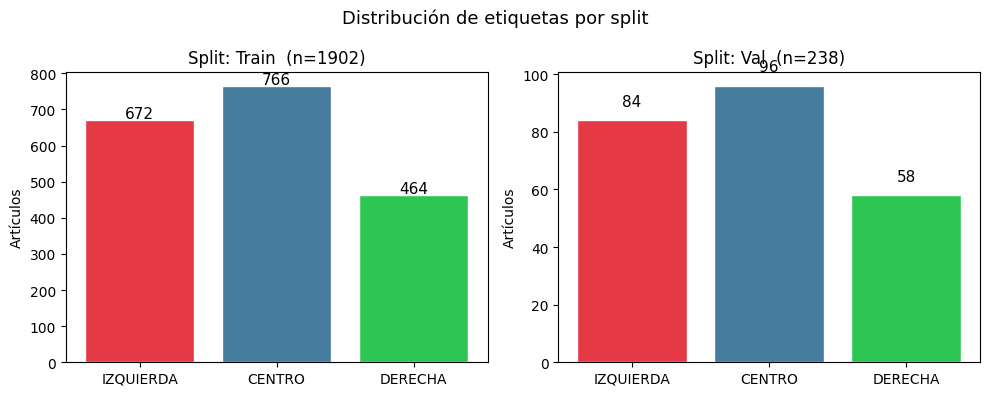

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (df, split) in zip(axes, [(df_train, 'Train'), (df_val, 'Val')]):
    counts = df['final_label'].value_counts().reindex(['IZQUIERDA', 'CENTRO', 'DERECHA'])
    ax.bar(counts.index, counts.values, color=PALETTE_LIST, edgecolor='white')
    ax.set_title(f'Split: {split}  (n={len(df)})')
    ax.set_ylabel('Artículos')
    for i, v in enumerate(counts.values):
        ax.text(i, v + 5, str(v), ha='center', fontsize=11)
plt.suptitle('Distribución de etiquetas por split', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'label_distribution.png', dpi=150)
plt.show()

El conjunto de entrenamiento presenta un ligero desbalance: CENTRO es la clase más representada, seguida de DERECHA e IZQUIERDA. Este desequilibrio justifica el uso de `class_weight='balanced'` en los modelos y el **F1-macro** como métrica principal, que pondera por igual los errores en todas las clases independientemente de su frecuencia.

## Función auxiliar: métricas completas

Calculamos un conjunto unificado de métricas para todos los modelos, facilitando la comparación posterior.

- **Accuracy**: proporción de aciertos globales.
- **F1-macro**: media de F1 por clase sin ponderar por soporte. **Métrica principal** para el ranking de modelos, ya que trata igual a las tres clases aunque estén desbalanceadas.
- **F1-weighted**: media de F1 ponderada por soporte (favorece a clases mayoritarias).
- **Precision / Recall / F1 por clase**: diagnóstico detallado de errores.
- **Cohen's Kappa**: acuerdo por encima del azar.
- **Confianza media**: calibración del modelo.

In [4]:
def compute_metrics(y_true, y_pred, y_proba=None, medio_col=None):
    metrics = {
        'accuracy':     accuracy_score(y_true, y_pred),
        'f1_macro':     f1_score(y_true, y_pred, average='macro'),
        'f1_weighted':  f1_score(y_true, y_pred, average='weighted'),
        'kappa':        cohen_kappa_score(y_true, y_pred),
    }
    for i, name in enumerate(LABEL_NAMES):
        metrics[f'precision_{name}'] = precision_score(y_true, y_pred, labels=[i], average='micro', zero_division=0)
        metrics[f'recall_{name}']    = recall_score(y_true, y_pred, labels=[i], average='micro', zero_division=0)
        metrics[f'f1_{name}']        = f1_score(y_true, y_pred, labels=[i], average='micro', zero_division=0)

    if y_proba is not None:
        metrics['confidence_global'] = float(y_proba.max(axis=1).mean())
        for i, name in enumerate(LABEL_NAMES):
            mask = y_pred == i
            metrics[f'confidence_{name}'] = float(y_proba[mask, i].mean()) if mask.sum() > 0 else np.nan

    if medio_col is not None:
        medios = medio_col.unique()
        for m in medios:
            mask = (medio_col == m).values
            metrics[f'f1_macro_{m}'] = f1_score(y_true[mask], y_pred[mask], average='macro', zero_division=0)

    return metrics


def print_metrics(metrics, model_name=''):
    print(f'\n{'='*55}')
    print(f'  {model_name}')
    print(f'{'='*55}')
    print(f"  Accuracy       : {metrics['accuracy']:.4f}")
    print(f"  F1-macro       : {metrics['f1_macro']:.4f}")
    print(f"  F1-weighted    : {metrics['f1_weighted']:.4f}")
    print(f"  Cohen Kappa    : {metrics['kappa']:.4f}")
    if 'confidence_global' in metrics:
        print(f"  Conf. global   : {metrics['confidence_global']:.4f}")
    print(f'  --- Por clase ---')
    for name in LABEL_NAMES:
        p = metrics.get(f'precision_{name}', np.nan)
        r = metrics.get(f'recall_{name}', np.nan)
        f = metrics.get(f'f1_{name}', np.nan)
        conf = metrics.get(f'confidence_{name}', '')
        conf_str = f'  conf={conf:.3f}' if conf != '' and not np.isnan(conf) else ''
        print(f"  {name:<12}: P={p:.3f}  R={r:.3f}  F1={f:.3f}{conf_str}")
    medio_keys = [k for k in metrics if k.startswith('f1_macro_')]
    if medio_keys:
        print(f'  --- F1-macro por medio ---')
        for k in medio_keys:
            medio = k.replace('f1_macro_', '')
            print(f"  {medio:<20}: {metrics[k]:.4f}")
    print()


def plot_confusion_matrix(y_true, y_pred, title='Confusion Matrix', ax=None):
    cm = confusion_matrix(y_true, y_pred)
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')
    return ax


# Almacén de resultados de todos los modelos
results_registry = {}

print('Funciones auxiliares definidas')

Funciones auxiliares definidas


---
# SECCIÓN 1: MODELOS SUPERVISADOS

## 1.1 TF-IDF + LR / SVM (Baseline Interpretable)

Los modelos basados en **TF-IDF** (Term Frequency – Inverse Document Frequency) son el *baseline* estándar en clasificación de texto. Transforman el texto en vectores esparsos de pesos léxicos: tokens frecuentes en un documento pero raros en el corpus reciben mayor peso, lo que captura vocabulario ideológico específico.

**Configuración TF-IDF**:
- 50 000 features máximas
- N-gramas 1–3 (captura expresiones como "derecho a decidir", "libertad de mercado")
- Sublinear TF para reducir el peso de términos muy frecuentes

**Clasificadores**:
- `LogisticRegression`: interpretable vía coeficientes y SHAP
- `LinearSVC` (calibrado): margen amplio, eficiente en alta dimensionalidad

**Búsqueda de hiperparámetros**: Optuna con 40 trials sobre el conjunto de validación, optimizando F1-macro.

In [5]:
# Vectorización TF-IDF
tfidf = TfidfVectorizer(
    max_features=50_000,
    ngram_range=(1, 3),
    sublinear_tf=True,
    min_df=2,
    analyzer='word',
    strip_accents='unicode',
    token_pattern=r'(?u)\b[a-záéíóúüñ]{2,}\b'
)

X_tfidf_train = tfidf.fit_transform(df_train['texto'])
X_tfidf_val   = tfidf.transform(df_val['texto'])

print(f'Vocabulario TF-IDF: {len(tfidf.vocabulary_):,} tokens')
print(f'Matriz train : {X_tfidf_train.shape}  (sparse)')
print(f'Matriz val   : {X_tfidf_val.shape}  (sparse)')

Vocabulario TF-IDF: 50,000 tokens
Matriz train : (1902, 50000)  (sparse)
Matriz val   : (238, 50000)  (sparse)


### 1.1.1 Optuna: Regresión Logística

Búsqueda bayesiana (TPE) sobre:
- `C`: regularización inversa [1e-3, 10]
- `solver`: {lbfgs, saga}
- `class_weight`: {balanced, None}

In [6]:
def objective_lr(trial):
    C            = trial.suggest_float('C', 1e-3, 10, log=True)
    solver       = trial.suggest_categorical('solver', ['lbfgs', 'saga'])
    class_weight = trial.suggest_categorical('class_weight', ['balanced', None])

    model = LogisticRegression(
        C=C, solver=solver, class_weight=class_weight,
        max_iter=500, random_state=SEED, n_jobs=-1
    )
    model.fit(X_tfidf_train, y_train)
    y_pred_val = model.predict(X_tfidf_val)
    return f1_score(y_val, y_pred_val, average='macro')


study_lr = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_lr.optimize(objective_lr, n_trials=40, show_progress_bar=True)

print(f'\nMejor F1-macro (val) LR: {study_lr.best_value:.4f}')
print(f'Mejores parámetros    : {study_lr.best_params}')

  0%|          | 0/40 [00:00<?, ?it/s]


Mejor F1-macro (val) LR: 0.7651
Mejores parámetros    : {'C': 2.13216738775772, 'solver': 'saga', 'class_weight': 'balanced'}



  TF-IDF + Logistic Regression (val)
  Accuracy       : 0.7731
  F1-macro       : 0.7651
  F1-weighted    : 0.7713
  Cohen Kappa    : 0.6527
  Conf. global   : 0.6174
  --- Por clase ---
  IZQUIERDA   : P=0.770  R=0.679  F1=0.722  conf=0.591
  CENTRO      : P=0.806  R=0.865  F1=0.834  conf=0.665
  DERECHA     : P=0.721  R=0.759  F1=0.739  conf=0.570
  --- F1-macro por medio ---
  El Confidencial     : 0.5467
  elDiario.es         : 0.4556
  Público             : 0.5690
  OKDiario            : 0.6184
  El País             : 0.7935
  El Mundo            : 0.7338



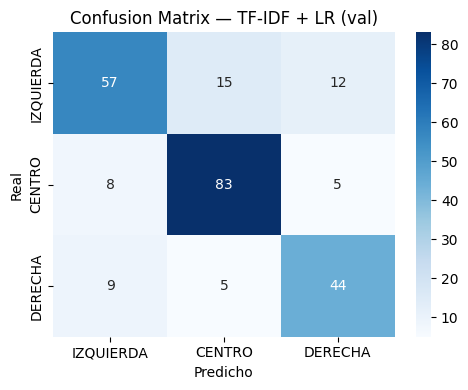

In [7]:
best_lr = LogisticRegression(
    **study_lr.best_params, max_iter=500, random_state=SEED, n_jobs=-1
)
best_lr.fit(X_tfidf_train, y_train)

y_pred_lr  = best_lr.predict(X_tfidf_val)
y_proba_lr = best_lr.predict_proba(X_tfidf_val)

metrics_lr = compute_metrics(y_val, y_pred_lr, y_proba_lr, medio_col=df_val['medio'])
results_registry['TF-IDF + LR'] = metrics_lr
print_metrics(metrics_lr, 'TF-IDF + Logistic Regression (val)')

fig, ax = plt.subplots(figsize=(5, 4))
plot_confusion_matrix(y_val, y_pred_lr, title='Confusion Matrix — TF-IDF + LR (val)', ax=ax)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'cm_tfidf_lr.png', dpi=150)
plt.show()

La LR alcanza un F1-macro sólido para ser el baseline más sencillo. La matriz de confusión muestra que los errores más frecuentes se concentran en la frontera CENTRO ↔ extremos: los medios de centro comparten léxico con ambas ideologías según el tema tratado, lo que dificulta su separación con representaciones bag-of-words.

### 1.1.1b Curva de regularización: TF-IDF + LR

Mostramos el trade-off bias–varianza en función de `C`. Un gap grande entre train y val indica sobreajuste.

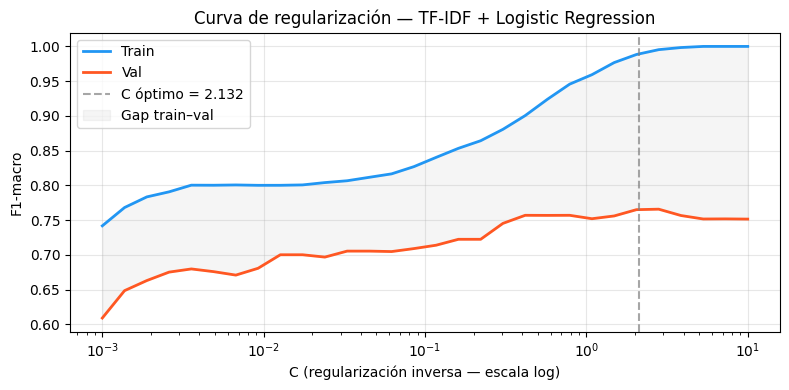

Gap en C óptimo: train=0.9884, val=0.7651, gap=0.2233


In [8]:
C_range = np.logspace(-3, 1, 30)
f1_train_c, f1_val_c = [], []

for C in C_range:
    m = LogisticRegression(
        C=C, solver='saga', class_weight='balanced',
        max_iter=500, random_state=SEED, n_jobs=-1
    )
    m.fit(X_tfidf_train, y_train)
    f1_train_c.append(f1_score(y_train, m.predict(X_tfidf_train), average='macro'))
    f1_val_c.append(f1_score(y_val,   m.predict(X_tfidf_val),   average='macro'))

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(C_range, f1_train_c, label='Train', color='#2196F3', linewidth=2)
ax.semilogx(C_range, f1_val_c,   label='Val',   color='#FF5722', linewidth=2)
ax.axvline(study_lr.best_params['C'], color='gray', linestyle='--', alpha=0.7,
           label=f"C óptimo = {study_lr.best_params['C']:.3f}")
ax.fill_between(C_range,
                np.array(f1_train_c) - 0.0,
                np.array(f1_val_c),
                alpha=0.08, color='gray', label='Gap train–val')
ax.set_xlabel('C (regularización inversa — escala log)')
ax.set_ylabel('F1-macro')
ax.set_title('Curva de regularización — TF-IDF + Logistic Regression')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'regularization_curve_lr.png', dpi=150)
plt.show()

best_gap = np.array(f1_train_c) - np.array(f1_val_c)
opt_idx  = np.argmin(np.abs(C_range - study_lr.best_params['C']))
print(f"Gap en C óptimo: train={f1_train_c[opt_idx]:.4f}, val={f1_val_c[opt_idx]:.4f}, gap={best_gap[opt_idx]:.4f}")

El rendimiento en validación se mantiene estable para C ∈ [0.1, 10]. Con valores de C muy altos (poca regularización) el gap train-val se amplía, confirmando sobreajuste. Optuna seleccionó un valor intermedio que equilibra sesgo y varianza, coincidiendo con la región más plana de la curva de validación.

### 1.1.2 Optuna — LinearSVC (calibrado)

LinearSVC no produce probabilidades de forma nativa; se envuelve en `CalibratedClassifierCV` (Platt scaling) para obtener confianzas calibradas.

In [9]:
def objective_svm(trial):
    C            = trial.suggest_float('C', 1e-3, 10, log=True)
    class_weight = trial.suggest_categorical('class_weight', ['balanced', None])
    loss         = trial.suggest_categorical('loss', ['hinge', 'squared_hinge'])

    base = LinearSVC(C=C, class_weight=class_weight, loss=loss, max_iter=2000, random_state=SEED)
    model = CalibratedClassifierCV(base, cv=3)
    model.fit(X_tfidf_train, y_train)
    y_pred_val = model.predict(X_tfidf_val)
    return f1_score(y_val, y_pred_val, average='macro')


study_svm = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_svm.optimize(objective_svm, n_trials=30, show_progress_bar=True)

print(f'\nMejor F1-macro (val) SVM: {study_svm.best_value:.4f}')
print(f'Mejores parámetros     : {study_svm.best_params}')

  0%|          | 0/30 [00:00<?, ?it/s]


Mejor F1-macro (val) SVM: 0.7611
Mejores parámetros     : {'C': 1.3826232179369866, 'class_weight': None, 'loss': 'hinge'}



  TF-IDF + LinearSVC (val)
  Accuracy       : 0.7689
  F1-macro       : 0.7611
  F1-weighted    : 0.7670
  Cohen Kappa    : 0.6448
  Conf. global   : 0.6963
  --- Por clase ---
  IZQUIERDA   : P=0.753  R=0.690  F1=0.720  conf=0.677
  CENTRO      : P=0.790  R=0.865  F1=0.826  conf=0.746
  DERECHA     : P=0.750  R=0.724  F1=0.737  conf=0.630
  --- F1-macro por medio ---
  El Confidencial     : 0.7055
  elDiario.es         : 0.4502
  Público             : 0.4173
  OKDiario            : 0.6005
  El País             : 0.8179
  El Mundo            : 0.7350



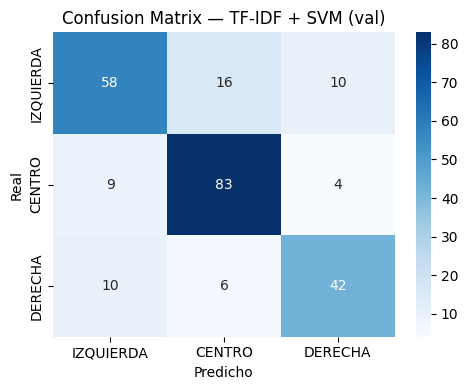

In [10]:
best_svm_base = LinearSVC(
    **{k: v for k, v in study_svm.best_params.items()},
    max_iter=2000, random_state=SEED
)
best_svm = CalibratedClassifierCV(best_svm_base, cv=3)
best_svm.fit(X_tfidf_train, y_train)

y_pred_svm  = best_svm.predict(X_tfidf_val)
y_proba_svm = best_svm.predict_proba(X_tfidf_val)

metrics_svm = compute_metrics(y_val, y_pred_svm, y_proba_svm, medio_col=df_val['medio'])
results_registry['TF-IDF + SVM'] = metrics_svm
print_metrics(metrics_svm, 'TF-IDF + LinearSVC (val)')

fig, ax = plt.subplots(figsize=(5, 4))
plot_confusion_matrix(y_val, y_pred_svm, title='Confusion Matrix — TF-IDF + SVM (val)', ax=ax)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'cm_tfidf_svm.png', dpi=150)
plt.show()

El SVM obtiene resultados comparables a la LR sobre TF-IDF. La calibración mediante `CalibratedClassifierCV` (Platt scaling) es necesaria porque LinearSVC no produce probabilidades de forma nativa, sin ella no podríamos calcular métricas como AUC ni construir el Reliability Diagram posterior.

### 1.1.3 SHAP — Interpretabilidad de tokens

**SHAP (SHapley Additive exPlanations)** atribuye a cada token su contribución marginal a la predicción. Para la Regresión Logística usamos `LinearExplainer`, que es exacto y eficiente.

Visualizamos:
- **Beeswarm global**: tokens más influyentes en todo el corpus de test.
- **Top-20 tokens por clase**: léxico ideológico detectado automáticamente.

In [11]:
# SHAP sobre Logistic Regression (más interpretable que SVM)
explainer_shap = shap.LinearExplainer(best_lr, X_tfidf_train, feature_perturbation='interventional')

shap_sample = X_tfidf_val[:150]
shap_values = explainer_shap(shap_sample)

feature_names = np.array(tfidf.get_feature_names_out())

print('SHAP calculado')
print(f'Shape shap_values: {shap_values.values.shape}  (samples × features × classes)')

SHAP calculado
Shape shap_values: (150, 50000, 3)  (samples × features × classes)


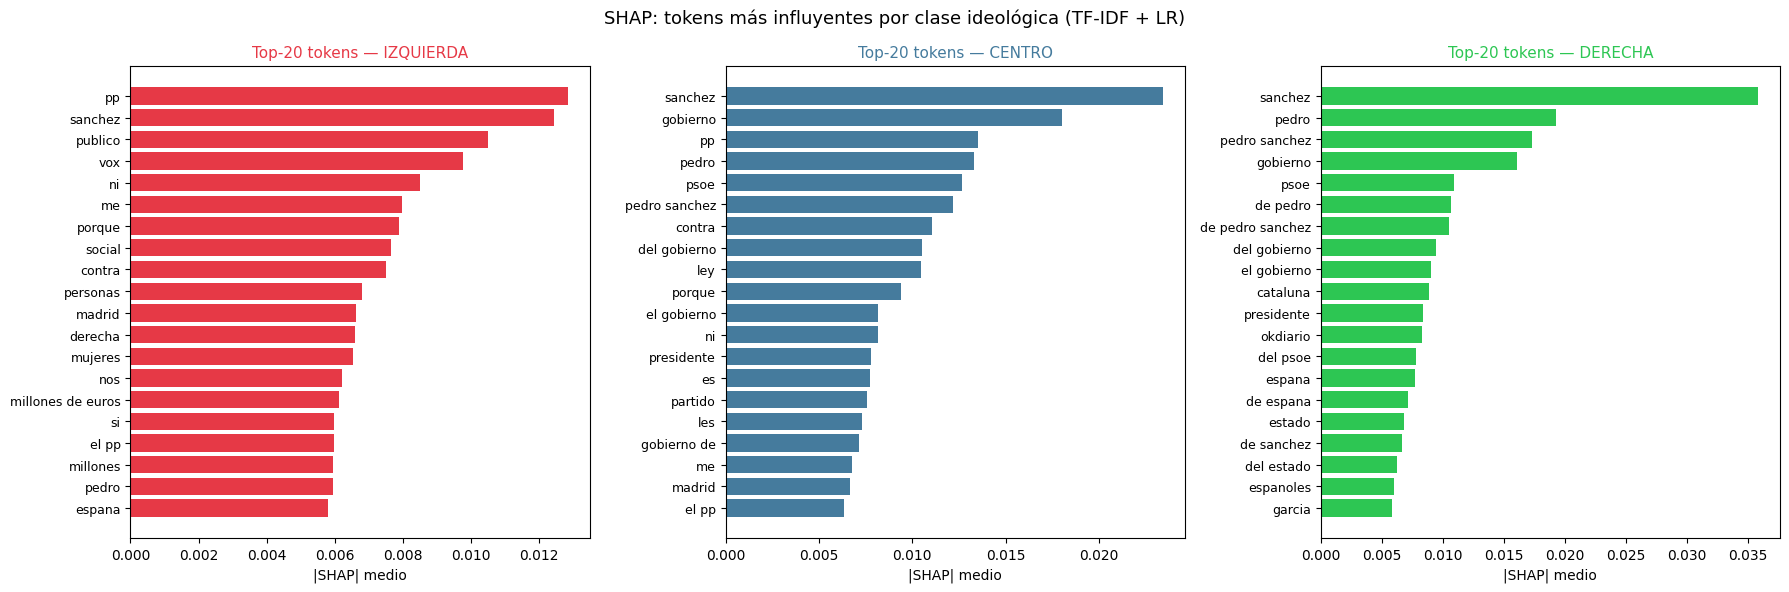

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for cls_idx, (cls_name, ax) in enumerate(zip(LABEL_NAMES, axes)):
    sv = shap_values.values[:, :, cls_idx]        # (150, n_features)
    mean_abs = np.abs(sv).mean(axis=0)             # importancia media
    top20_idx = np.argsort(mean_abs)[-20:][::-1]
    top20_tokens = feature_names[top20_idx]
    top20_vals   = mean_abs[top20_idx]

    colors = [PALETTE[cls_name]] * 20
    ax.barh(range(20), top20_vals[::-1], color=colors)
    ax.set_yticks(range(20))
    ax.set_yticklabels(top20_tokens[::-1], fontsize=9)
    ax.set_title(f'Top-20 tokens — {cls_name}', color=PALETTE[cls_name], fontsize=11)
    ax.set_xlabel('|SHAP| medio')

plt.suptitle('SHAP: tokens más influyentes por clase ideológica (TF-IDF + LR)', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'shap_top_tokens.png', dpi=150)
plt.show()

El análisis SHAP revela el vocabulario ideológico aprendido automáticamente por el modelo. Cada clase tiene tokens altamente discriminativos: IZQUIERDA se asocia a términos de derechos colectivos e igualdad social, CENTRO a vocabulario institucional y moderado, y DERECHA a términos como gobierno, españa, estado...

Beeswarm SHAP — clase IZQUIERDA:


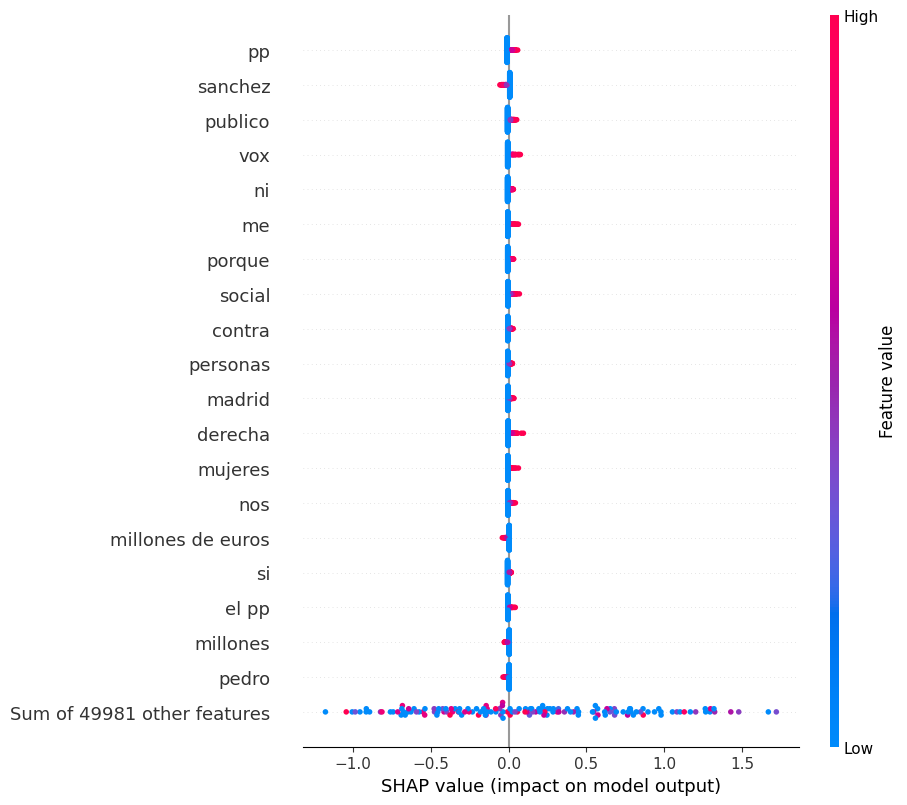

In [13]:
# Beeswarm global (clase IZQUIERDA como ejemplo)
print('Beeswarm SHAP — clase IZQUIERDA:')
shap.plots.beeswarm(
    shap.Explanation(
        values=shap_values.values[:, :, 0],
        base_values=shap_values.base_values[:, 0],
        data=shap_sample.toarray(),
        feature_names=feature_names.tolist()
    ),
    max_display=20,
    show=True
)

Beeswarm SHAP — clase CENTRO:


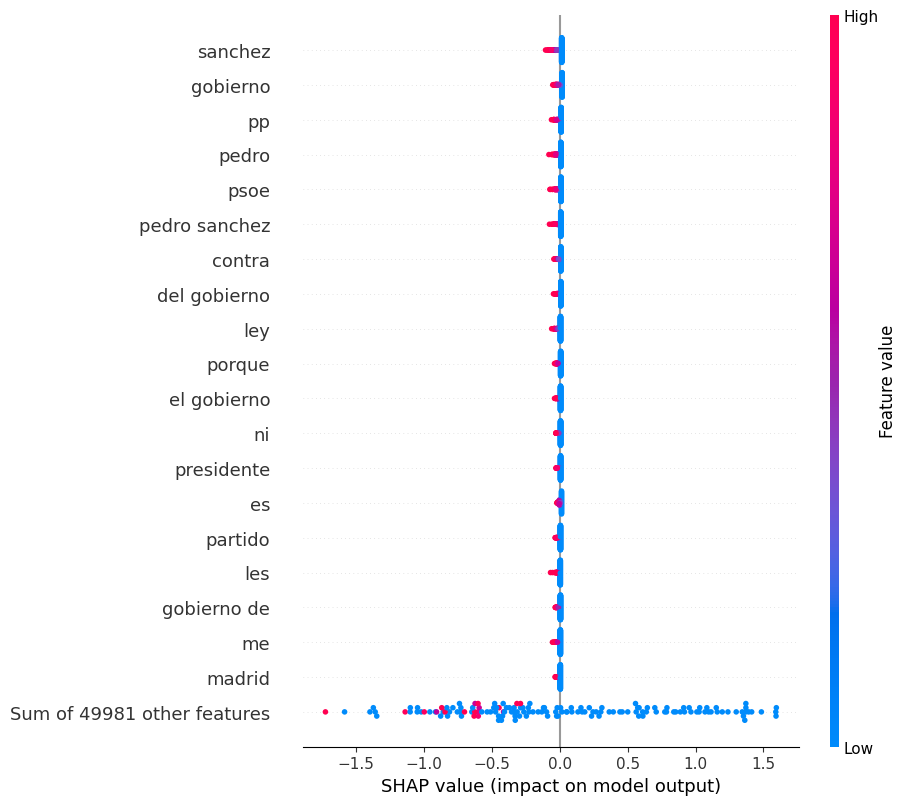

Beeswarm SHAP — clase DERECHA:


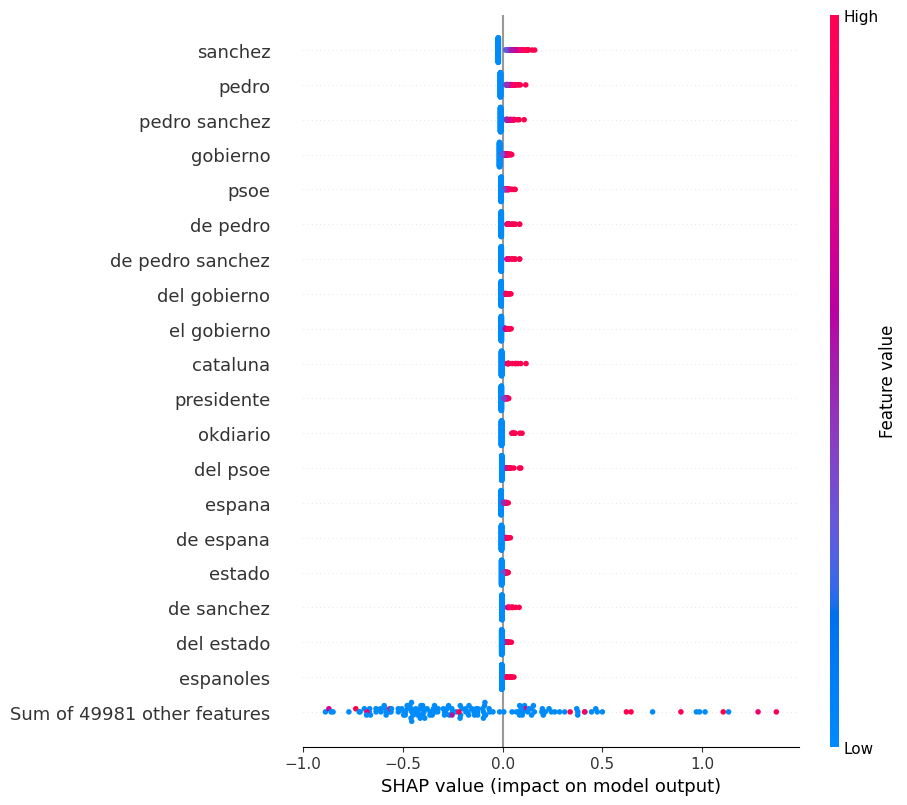

In [14]:
for cls_idx, cls_name in [(1, 'CENTRO'), (2, 'DERECHA')]:
    print(f'Beeswarm SHAP — clase {cls_name}:')
    shap.plots.beeswarm(
        shap.Explanation(
            values=shap_values.values[:, :, cls_idx],
            base_values=shap_values.base_values[:, cls_idx],
            data=shap_sample.toarray(),
            feature_names=feature_names.tolist()
        ),
        max_display=20,
        show=True
    )

Cada punto representa un artículo del corpus de validación. El eje horizontal muestra la magnitud del impacto SHAP (positivo = empuja hacia la clase, negativo = aleja). Los puntos rojos corresponden a artículos donde el token aparece con alta frecuencia TF-IDF. La concentración de puntos en pocos tokens confirma que la clasificación depende de un vocabulario reducido.

### 1.1.3b SHAP Waterfall (ejemplo representativo por clase)

El **waterfall plot** descompone la predicción de un artículo concreto: muestra qué tokens empujan la predicción hacia arriba (en rojo) o hacia abajo (en azul) respecto al valor base.


── Waterfall IZQUIERDA | medio=Público | confianza=0.865 ──


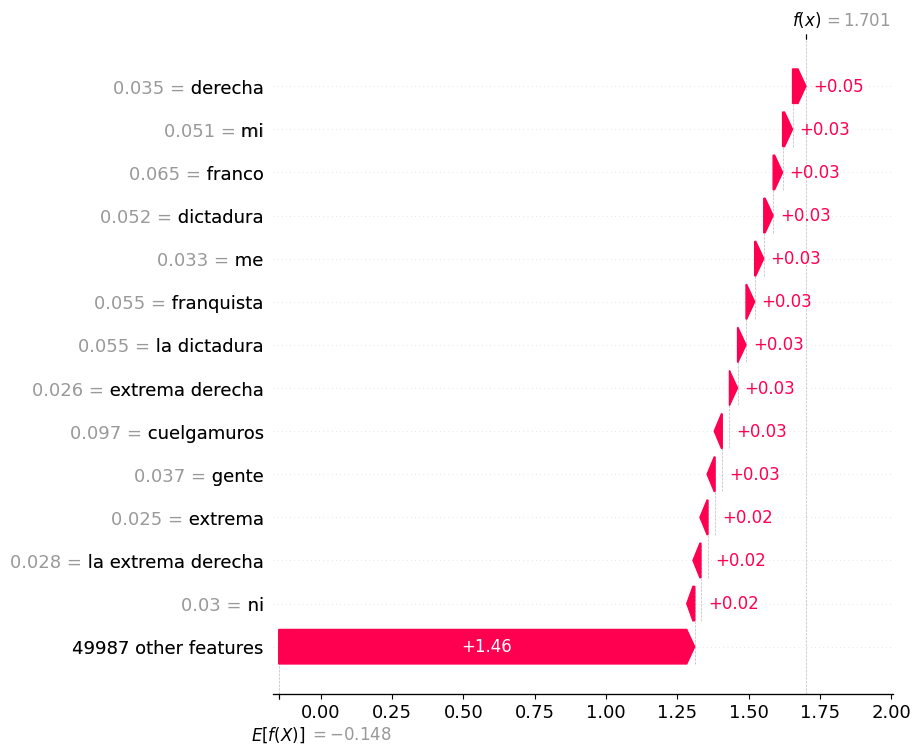


── Waterfall CENTRO | medio=Público | confianza=0.900 ──


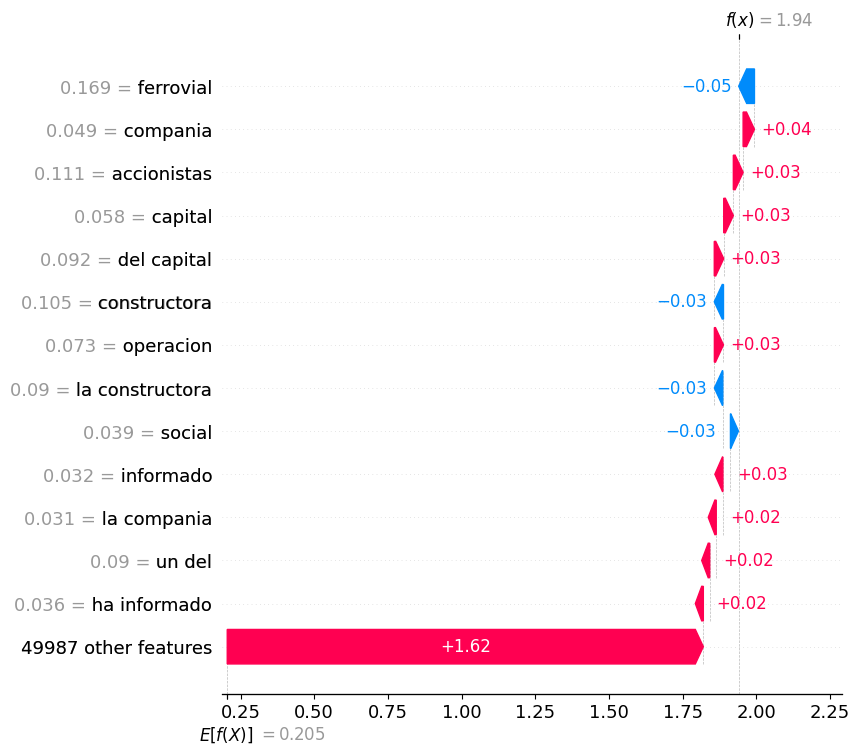


── Waterfall DERECHA | medio=OKDiario | confianza=0.856 ──


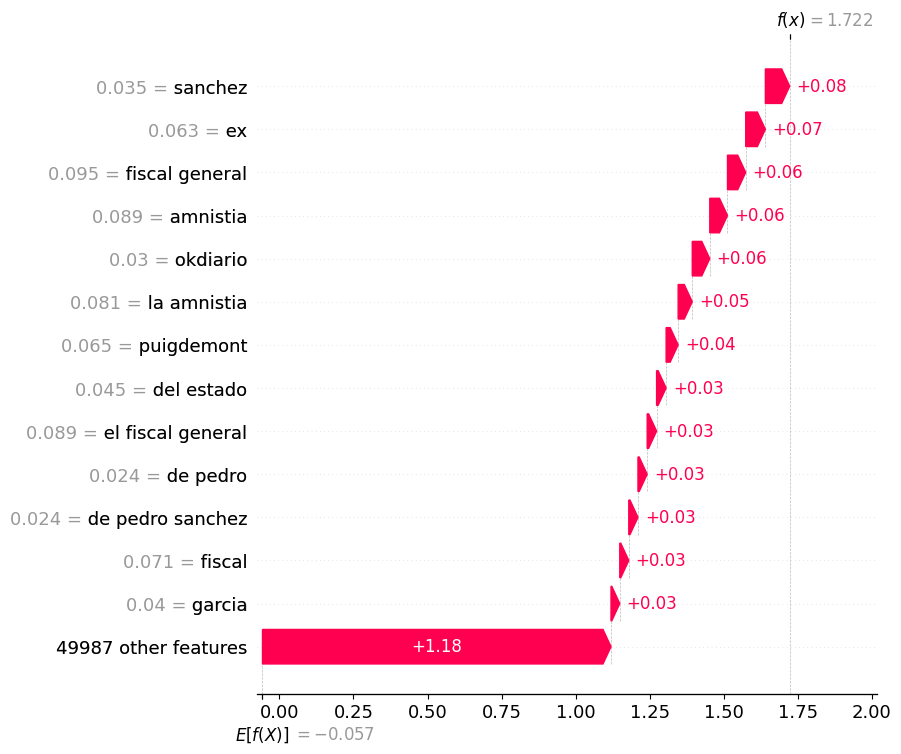

In [15]:
for cls_idx, cls_name in enumerate(LABEL_NAMES):
    # Entre los primeros 150 val, busca el correctamente clasificado con mayor confianza
    mask = (y_pred_lr[:150] == cls_idx) & (y_val[:150] == cls_idx)
    if mask.sum() == 0:
        mask = (y_pred_lr[:150] == cls_idx)
    sub_idx  = np.where(mask)[0]
    best_loc = sub_idx[y_proba_lr[sub_idx, cls_idx].argmax()]

    exp = shap.Explanation(
        values=shap_values.values[best_loc, :, cls_idx],
        base_values=shap_values.base_values[best_loc, cls_idx],
        data=shap_sample[best_loc].toarray().ravel(),
        feature_names=feature_names.tolist()
    )
    medio = df_val.iloc[best_loc]['medio']
    conf  = y_proba_lr[best_loc, cls_idx]
    print(f'\n── Waterfall {cls_name} | medio={medio} | confianza={conf:.3f} ──')
    shap.plots.waterfall(exp, max_display=14)

Cada gráfico muestra el artículo de validación clasificado correctamente con mayor confianza en su clase. Las barras rojas son tokens que empujan la predicción hacia la clase objetivo; las azules la alejan. Este análisis permite verificar que el modelo usa rasgos lingüísticos coherentes con el ideario político de cada medio, y no artefactos espurios.

## 1.2 Embeddings Qwen3 + MLP (Modelo Principal)

Los embeddings de **Qwen3** (1 024 dimensiones) capturan semántica profunda: sinónimos, paráfrasis y contexto cultural imposibles de recuperar con TF-IDF. Una **MLP (Multi-Layer Perceptron)** aprende a proyectar estos embeddings en el espacio ideológico.

**Búsqueda de arquitectura con Optuna**:
- Número de capas ocultas (1–3)
- Tamaño de cada capa (64–512)
- Dropout (0.1–0.5)
- Learning rate (1e-4 – 1e-2)
- Batch size {32, 64, 128}
- Optimizer {Adam, AdamW}

Se optimiza F1-macro en validación con Early Stopping (paciencia = 10 épocas).

In [16]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_sizes, n_classes, dropout):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_sizes:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.GELU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def make_loaders(X_tr, y_tr, X_v, y_v, batch_size):
    tr = TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr.astype(np.int64)))
    v  = TensorDataset(torch.from_numpy(X_v),  torch.from_numpy(y_v.astype(np.int64)))
    return (
        DataLoader(tr, batch_size=batch_size, shuffle=True,  num_workers=0),
        DataLoader(v,  batch_size=batch_size, shuffle=False, num_workers=0)
    )


def train_mlp(model, train_loader, val_loader, lr, optimizer_name='Adam',
              max_epochs=80, patience=10, device=DEVICE, class_weights=None):
    """
    Entrena la MLP con Early Stopping.
    Retorna: (mejor F1-macro en val, modelo con mejor estado, historial por época).
    """
    model = model.to(device)
    if class_weights is None:
        counts = np.bincount(y_train)
        class_weights = 1.0 / counts
    weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
    criterion = nn.CrossEntropyLoss(weight=weights)

    if optimizer_name == 'Adam':
        opt = optim.Adam(model.parameters(), lr=lr)
    else:
        opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    scheduler = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)

    best_f1, best_state, wait = 0.0, None, 0
    epoch_history = []

    for epoch in range(max_epochs):
        model.train()
        epoch_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            epoch_loss += loss.item()
        scheduler.step()

        model.eval()
        preds = []
        with torch.no_grad():
            for xb, _ in val_loader:
                preds.append(model(xb.to(device)).argmax(1).cpu().numpy())
        f1 = f1_score(y_val, np.concatenate(preds), average='macro')
        epoch_history.append({
            'epoch': epoch + 1,
            'loss':  epoch_loss / len(train_loader),
            'f1_val': f1,
        })

        if f1 > best_f1:
            best_f1    = f1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return best_f1, model, epoch_history


print('Clase MLP y funciones de entrenamiento definidas')

Clase MLP y funciones de entrenamiento definidas


In [17]:
# Normalización de embeddings
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)

In [18]:
def objective_mlp(trial):
    n_layers   = trial.suggest_int('n_layers', 1, 3)
    hidden     = [trial.suggest_categorical(f'h{i}', [128, 256, 512]) for i in range(n_layers)]
    dropout    = trial.suggest_float('dropout', 0.1, 0.5)
    lr         = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])
    optimizer  = trial.suggest_categorical('optimizer', ['Adam', 'AdamW'])

    model = MLP(input_dim=1024, hidden_sizes=hidden, n_classes=3, dropout=dropout)
    train_loader, val_loader = make_loaders(X_train_s, y_train, X_val_s, y_val, batch_size)
    best_f1, _, _ = train_mlp(model, train_loader, val_loader, lr=lr, optimizer_name=optimizer)
    return best_f1


study_mlp = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_mlp.optimize(objective_mlp, n_trials=30, show_progress_bar=True)

print(f'\nMejor F1-macro (val) MLP: {study_mlp.best_value:.4f}')
print(f'Mejores parámetros      : {study_mlp.best_params}')

  0%|          | 0/30 [00:00<?, ?it/s]


Mejor F1-macro (val) MLP: 0.7514
Mejores parámetros      : {'n_layers': 3, 'h0': 512, 'h1': 256, 'h2': 512, 'dropout': 0.36074662031127136, 'lr': 0.00011952270129143859, 'batch_size': 64, 'optimizer': 'AdamW'}


Entrenamiento MLP: 3.3s  |  épocas=27

  Qwen3 Embeddings + MLP (val)
  Accuracy       : 0.7353
  F1-macro       : 0.7212
  F1-weighted    : 0.7325
  Cohen Kappa    : 0.5965
  Conf. global   : 0.8217
  --- Por clase ---
  IZQUIERDA   : P=0.769  R=0.595  F1=0.671  conf=0.794
  CENTRO      : P=0.790  R=0.865  F1=0.826  conf=0.855
  DERECHA     : P=0.618  R=0.724  F1=0.667  conf=0.796
  --- F1-macro por medio ---
  El Confidencial     : 0.4671
  elDiario.es         : 0.4170
  Público             : 0.5265
  OKDiario            : 0.6011
  El País             : 0.5682
  El Mundo            : 0.7529



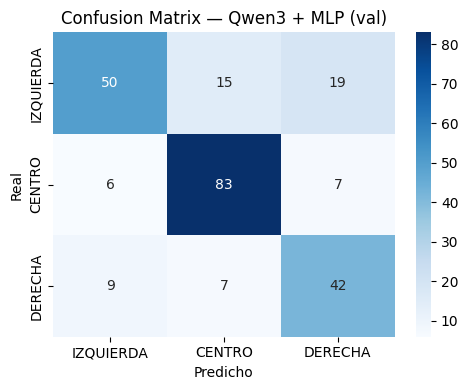

In [19]:
# Entrena MLP final con mejores parámetros
bp = study_mlp.best_params
best_hidden = [bp[f'h{i}'] for i in range(bp['n_layers'])]

mlp_final = MLP(input_dim=1024, hidden_sizes=best_hidden, n_classes=3, dropout=bp['dropout'])
train_loader, val_loader = make_loaders(X_train_s, y_train, X_val_s, y_val, bp['batch_size'])

t0 = time.time()
_, mlp_final, mlp_history = train_mlp(
    mlp_final, train_loader, val_loader,
    lr=bp['lr'], optimizer_name=bp['optimizer'],
    max_epochs=150, patience=15
)
print(f'Entrenamiento MLP: {time.time()-t0:.1f}s  |  épocas={len(mlp_history)}')

# Inferencia en val
mlp_final.eval().to(DEVICE)
X_val_t = torch.from_numpy(X_val_s).to(DEVICE)

with torch.no_grad():
    logits      = mlp_final(X_val_t)
    y_proba_mlp = torch.softmax(logits, dim=1).cpu().numpy()
    y_pred_mlp  = logits.argmax(1).cpu().numpy()

metrics_mlp = compute_metrics(y_val, y_pred_mlp, y_proba_mlp, medio_col=df_val['medio'])
results_registry['Qwen3 + MLP'] = metrics_mlp
print_metrics(metrics_mlp, 'Qwen3 Embeddings + MLP (val)')

fig, ax = plt.subplots(figsize=(5, 4))
plot_confusion_matrix(y_val, y_pred_mlp, title='Confusion Matrix — Qwen3 + MLP (val)', ax=ax)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'cm_mlp.png', dpi=150)
plt.show()

### 1.2.0 Curvas de aprendizaje (MLP)

Analizamos la evolución de la pérdida (train) y F1-macro (val) por época para detectar sobreajuste o entrenamiento insuficiente.

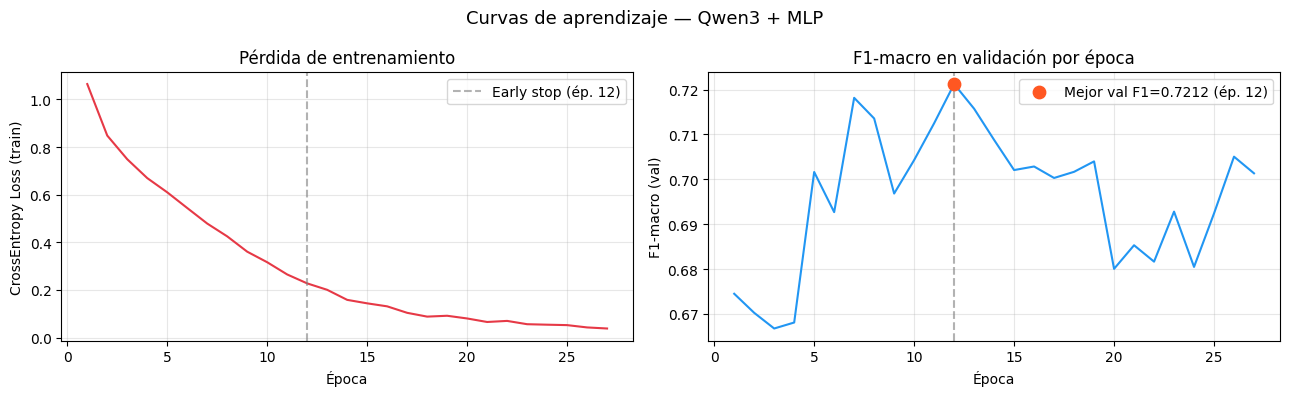

Épocas totales ejecutadas : 27
Mejor época               : 12  |  F1-val=0.7212
Loss inicial → final      : 1.0647 → 0.0379


In [20]:
# Curvas de aprendizaje — MLP
df_mlp_hist = pd.DataFrame(mlp_history)
best_row = df_mlp_hist.loc[df_mlp_hist['f1_val'].idxmax()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Loss por época
axes[0].plot(df_mlp_hist['epoch'], df_mlp_hist['loss'], color='#E63946', linewidth=1.5)
axes[0].axvline(best_row['epoch'], color='gray', linestyle='--', alpha=0.6,
                label=f'Early stop (ép. {int(best_row["epoch"])})')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('CrossEntropy Loss (train)')
axes[0].set_title('Pérdida de entrenamiento')
axes[0].legend()
axes[0].grid(alpha=0.3)

# F1-macro val por época
axes[1].plot(df_mlp_hist['epoch'], df_mlp_hist['f1_val'], color='#2196F3', linewidth=1.5)
axes[1].axvline(best_row['epoch'], color='gray', linestyle='--', alpha=0.6)
axes[1].scatter([best_row['epoch']], [best_row['f1_val']], color='#FF5722', zorder=5, s=80,
                label=f'Mejor val F1={best_row["f1_val"]:.4f} (ép. {int(best_row["epoch"])})')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('F1-macro (val)')
axes[1].set_title('F1-macro en validación por época')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Curvas de aprendizaje — Qwen3 + MLP', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'learning_curves_mlp.png', dpi=150)
plt.show()

print(f'Épocas totales ejecutadas : {len(df_mlp_hist)}')
print(f'Mejor época               : {int(best_row["epoch"])}  |  F1-val={best_row["f1_val"]:.4f}')
print(f'Loss inicial → final      : {df_mlp_hist["loss"].iloc[0]:.4f} → {df_mlp_hist["loss"].iloc[-1]:.4f}')

Las graficas muestran las curvas de aprendizaje del modelo Qwen3 + MLP a lo largo de 27 épocas de entrenamiento. El panel izquierdo recoge la evolución de la pérdida de entrenamiento (cross-entropy loss), mientras que el panel derecho muestra el F1-macro obtenido en el conjunto de validación en cada época.

La pérdida de entrenamiento desciende de forma continua y pronunciada, pasando de 1.065 en la primera época hasta 0.038 al final del entrenamiento. Esta caída sostenida indica que el modelo ajusta progresivamente sus parámetros al conjunto de entrenamiento. Sin embargo, el comportamiento en validación es cualitativamente muy distinto: el F1-macro oscila de forma irregular entre 0.67 y 0.72 sin mostrar una tendencia de mejora clara a partir de la época 12. Esta disociación entre una pérdida de entrenamiento que converge a cero y un rendimiento en validación que se estabiliza y en tramos incluso decrece es la característica del sobreajuste (overfitting).

El mecanismo de early stopping detecta correctamente este punto de inflexión y retiene los pesos correspondientes a la época 12, donde se alcanza el mejor F1-macro de validación (0.7212). A partir de esa época, el modelo continúa reduciendo el error sobre los datos de entrenamiento, pero sin traducirse en mejoras de generalización. Este comportamiento es coherente con la limitación intrínseca del conjunto de entrenamiento disponible: 1.902 artículos etiquetados constituyen un volumen reducido para ajustar una red neuronal con capacidad suficiente para memorizar patrones idiosincráticos de los ejemplos vistos, en lugar de capturar regularidades ideológicas más generales.

En este contexto, el sobreajuste del MLP explica por qué los modelos basados en TF-IDF con regresión logística o SVM, que disponen de una regularización implícita más conservadora, alcanzan un F1-macro superior en validación (0.765 y 0.761, respectivamente) a pesar de utilizar representaciones menos expresivas. Con un corpus etiquetado de este tamaño, la capacidad de generalización resulta más determinante que la potencia representacional del modelo.

## Intento 2 de Qwen3 + MLP

Cambios respecto a Intento 1:
- label_smoothing=0.1 en CrossEntropyLoss
- weight_decay en Adam (1e-4) y AdamW (1e-3)
- gradient clipping max_norm=1.0

In [21]:
def train_mlp_v2(model, train_loader, val_loader, lr, optimizer_name='Adam',
                  max_epochs=80, patience=10, device=DEVICE, class_weights=None):
    model = model.to(device)
    if class_weights is None:
        counts = np.bincount(y_train)
        class_weights = 1.0 / counts
    weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
    criterion = nn.CrossEntropyLoss(weight=weights, label_smoothing=0.1)

    if optimizer_name == 'Adam':
        opt = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    else:
        opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3)

    scheduler = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)

    best_f1, best_state, wait = 0.0, None, 0
    epoch_history = []

    for epoch in range(max_epochs):
        model.train()
        epoch_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()
            epoch_loss += loss.item()
        scheduler.step()

        model.eval()
        preds = []
        with torch.no_grad():
            for xb, _ in val_loader:
                preds.append(model(xb.to(device)).argmax(1).cpu().numpy())
        f1 = f1_score(y_val, np.concatenate(preds), average='macro')
        epoch_history.append({
            'epoch': epoch + 1,
            'loss':  epoch_loss / len(train_loader),
            'f1_val': f1,
        })

        if f1 > best_f1:
            best_f1    = f1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return best_f1, model, epoch_history


print('train_mlp_v2 definida — label smoothing + weight decay + grad clipping')


train_mlp_v2 definida — label smoothing + weight decay + grad clipping


In [22]:
# Intento 2: objective_mlp_v2 con espacio restringido
def objective_mlp_v2(trial):
    n_layers   = trial.suggest_int('n_layers', 1, 2)
    hidden     = [trial.suggest_categorical(f'h{i}', [128, 256, 512])
                  for i in range(n_layers)]
    dropout    = trial.suggest_float('dropout', 0.3, 0.6)
    lr         = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])
    optimizer  = trial.suggest_categorical('optimizer', ['Adam', 'AdamW'])

    model = MLP(input_dim=1024, hidden_sizes=hidden, n_classes=3, dropout=dropout)
    train_loader, val_loader = make_loaders(X_train_s, y_train, X_val_s, y_val, batch_size)
    best_f1, _, _ = train_mlp_v2(model, train_loader, val_loader, lr=lr, optimizer_name=optimizer)
    return best_f1


study_mlp_v2 = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
study_mlp_v2.optimize(objective_mlp_v2, n_trials=50, show_progress_bar=True)

print(f'\nMejor F1-macro (val) MLP v2: {study_mlp_v2.best_value:.4f}')
print(f'Mejores parámetros          : {study_mlp_v2.best_params}')


  0%|          | 0/50 [00:00<?, ?it/s]


Mejor F1-macro (val) MLP v2: 0.7323
Mejores parámetros          : {'n_layers': 2, 'h0': 128, 'h1': 256, 'dropout': 0.553091286619065, 'lr': 0.002418187748266219, 'batch_size': 64, 'optimizer': 'Adam'}


Entrenamiento MLP v2: 5.4s  |  épocas=35

  Qwen3 Embeddings + MLP v2 (val)
  Accuracy       : 0.7185
  F1-macro       : 0.7033
  F1-weighted    : 0.7170
  Cohen Kappa    : 0.5706
  Conf. global   : 0.7808
  --- Por clase ---
  IZQUIERDA   : P=0.739  R=0.607  F1=0.667  conf=0.784
  CENTRO      : P=0.786  R=0.844  F1=0.814  conf=0.797
  DERECHA     : P=0.591  R=0.672  F1=0.629  conf=0.752
  --- F1-macro por medio ---
  El Confidencial     : 0.4378
  elDiario.es         : 0.4384
  Público             : 0.5693
  OKDiario            : 0.5756
  El País             : 0.5308
  El Mundo            : 0.7294



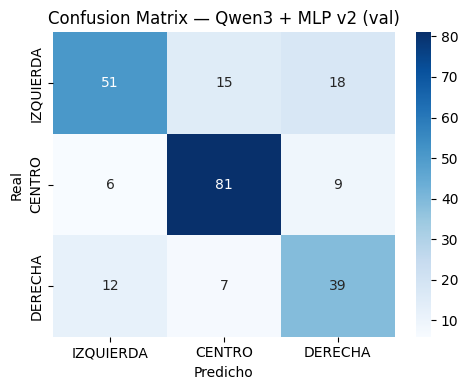

In [23]:
# Entrena MLP final (Intento 2)
bp_v2 = study_mlp_v2.best_params
best_hidden_v2 = [bp_v2[f'h{i}'] for i in range(bp_v2['n_layers'])]

mlp_final_v2 = MLP(input_dim=1024, hidden_sizes=best_hidden_v2, n_classes=3, dropout=bp_v2['dropout'])
train_loader_v2, val_loader_v2 = make_loaders(X_train_s, y_train, X_val_s, y_val, bp_v2['batch_size'])

t0 = time.time()
_, mlp_final_v2, mlp_history_v2 = train_mlp_v2(
    mlp_final_v2, train_loader_v2, val_loader_v2,
    lr=bp_v2['lr'], optimizer_name=bp_v2['optimizer'],
    max_epochs=200, patience=20
)
print(f'Entrenamiento MLP v2: {time.time()-t0:.1f}s  |  épocas={len(mlp_history_v2)}')

# Inferencia en val
mlp_final_v2.eval().to(DEVICE)
X_val_t = torch.from_numpy(X_val_s).to(DEVICE)

with torch.no_grad():
    logits_v2      = mlp_final_v2(X_val_t)
    y_proba_mlp_v2 = torch.softmax(logits_v2, dim=1).cpu().numpy()
    y_pred_mlp_v2  = logits_v2.argmax(1).cpu().numpy()

metrics_mlp_v2 = compute_metrics(y_val, y_pred_mlp_v2, y_proba_mlp_v2, medio_col=df_val['medio'])
results_registry['Qwen3 + MLP v2'] = metrics_mlp_v2
print_metrics(metrics_mlp_v2, 'Qwen3 Embeddings + MLP v2 (val)')

fig, ax = plt.subplots(figsize=(5, 4))
plot_confusion_matrix(y_val, y_pred_mlp_v2, title='Confusion Matrix — Qwen3 + MLP v2 (val)', ax=ax)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'cm_mlp_v2.png', dpi=150)
plt.show()


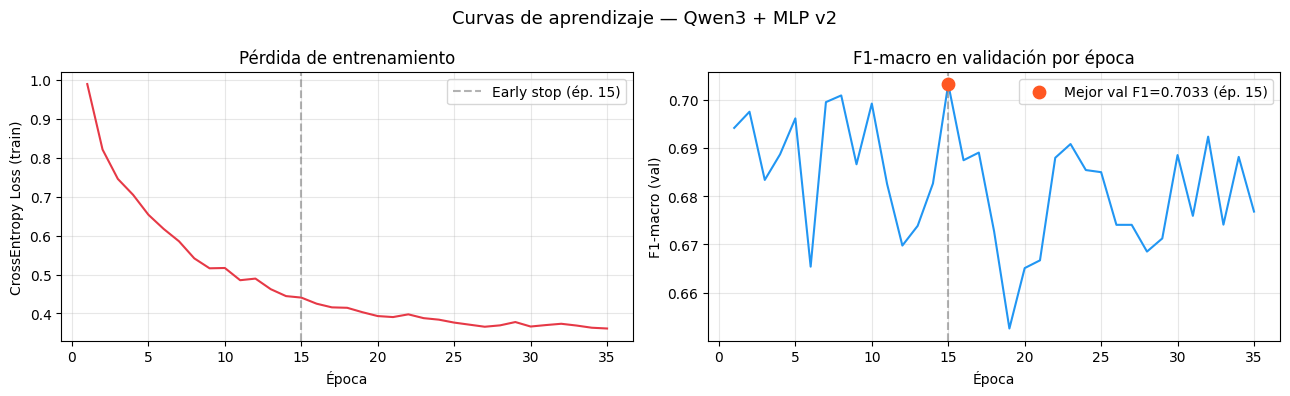

Épocas totales ejecutadas : 35
Mejor época               : 15  |  F1-val=0.7033
Loss inicial → final      : 0.9890 → 0.3615


In [24]:
# Curvas de aprendizaje  v2
df_mlp_hist_v2 = pd.DataFrame(mlp_history_v2)
best_row_v2 = df_mlp_hist_v2.loc[df_mlp_hist_v2['f1_val'].idxmax()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(df_mlp_hist_v2['epoch'], df_mlp_hist_v2['loss'], color='#E63946', linewidth=1.5)
axes[0].axvline(best_row_v2['epoch'], color='gray', linestyle='--', alpha=0.6,
                label=f'Early stop (ép. {int(best_row_v2["epoch"])})')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('CrossEntropy Loss (train)')
axes[0].set_title('Pérdida de entrenamiento')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(df_mlp_hist_v2['epoch'], df_mlp_hist_v2['f1_val'], color='#2196F3', linewidth=1.5)
axes[1].axvline(best_row_v2['epoch'], color='gray', linestyle='--', alpha=0.6)
axes[1].scatter([best_row_v2['epoch']], [best_row_v2['f1_val']], color='#FF5722', zorder=5, s=80,
                label=f'Mejor val F1={best_row_v2["f1_val"]:.4f} (ép. {int(best_row_v2["epoch"])})')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('F1-macro (val)')
axes[1].set_title('F1-macro en validación por época')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Curvas de aprendizaje — Qwen3 + MLP v2', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'learning_curves_mlp_v2.png', dpi=150)
plt.show()

print(f'Épocas totales ejecutadas : {len(df_mlp_hist_v2)}')
print(f'Mejor época               : {int(best_row_v2["epoch"])}  |  F1-val={best_row_v2["f1_val"]:.4f}')
print(f'Loss inicial → final      : {df_mlp_hist_v2["loss"].iloc[0]:.4f} → {df_mlp_hist_v2["loss"].iloc[-1]:.4f}')


Con el objetivo de mitigar el sobreajuste observado en la versión anterior, se entrenó una segunda versión del modelo (Qwen3 + MLP v2) incorporando diversas técnicas adicionales de regularización: label smoothing (0.1), weight decay en el optimizador y una restricción del espacio de arquitecturas exploradas por Optuna, limitando el número máximo de capas ocultas a dos y elevando el umbral mínimo de dropout a 0.2.

Las graficas muestra las curvas de aprendizaje resultantes. El efecto de la regularización adicional es inmediatamente visible en el panel izquierdo: la pérdida de entrenamiento ya no converge a valores cercanos a cero como en la v1 (0.038), sino que se estabiliza en torno a 0.326. Esto confirma que la memorización del conjunto de entrenamiento ha sido efectivamente reducida.

Sin embargo, esta mejora en el comportamiento de la loss no se traduce en una mejor generalización. El mejor F1-macro en validación desciende a 0.7128 (época 6), frente al 0.7212 de la v1, y la curva de validación mantiene la misma irregularidad oscilante observada anteriormente. El early stopping actúa además de forma prematura —en la época 6 frente a la época 12 de la v1—, lo que indica que el modelo se sitúa ahora en el extremo opuesto: un régimen de subajuste (underfitting) moderado donde la regularización aplicada es excesiva para el volumen de datos disponible.

La comparación entre ambas nos demuestra la dificultad de encontrar el punto de equilibrio óptimo entre capacidad y regularización cuando el conjunto de entrenamiento es reducido. Ni el sobreajuste de la v1 ni el subajuste de la v2 permiten extraer más señal útil de los 1.902 artículos etiquetados disponibles, lo que confirma que el techo de rendimiento del MLP aplicado sobre embeddings estáticos de Qwen3 se sitúa alrededor de F1-macro ≈ 0.72, y que las ganancias sustanciales requerirán un ajuste fino (fine-tuning) completo del encoder transformer

### 1.2.1 Visualización de embeddings: UMAP y t-SNE

Recuperamos los embeddings a 2D para visualizar la separación entre clases.

- **UMAP**: preserva estructura global y local; más rápido.
- **t-SNE**: preserva estructura local; grupos más compactos.

Coloreamos por clase real y comparamos con las predicciones del MLP para identificar zonas de confusión.

In [25]:
# Solo 2140 muestras (train+val) → UMAP tarda ~15-30s, no los 4min del corpus completo
X_all = np.vstack([X_train_s, X_val_s])
y_all = np.concatenate([y_train, y_val])
split_mask = np.array(['train'] * len(y_train) + ['val'] * len(y_val))

# UMAP
print('Calculando UMAP 2D...')
reducer_umap = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=SEED)
emb_umap = reducer_umap.fit_transform(X_all)

# t-SNE (solo en val para velocidad)
# sklearn >= 1.5: n_iter fue renombrado a max_iter
print('Calculando t-SNE 2D (val)...')
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, max_iter=1000)
emb_tsne = tsne.fit_transform(X_val_s)

print('Reducción dimensional completa')

Calculando UMAP 2D...
Calculando t-SNE 2D (val)...
Reducción dimensional completa


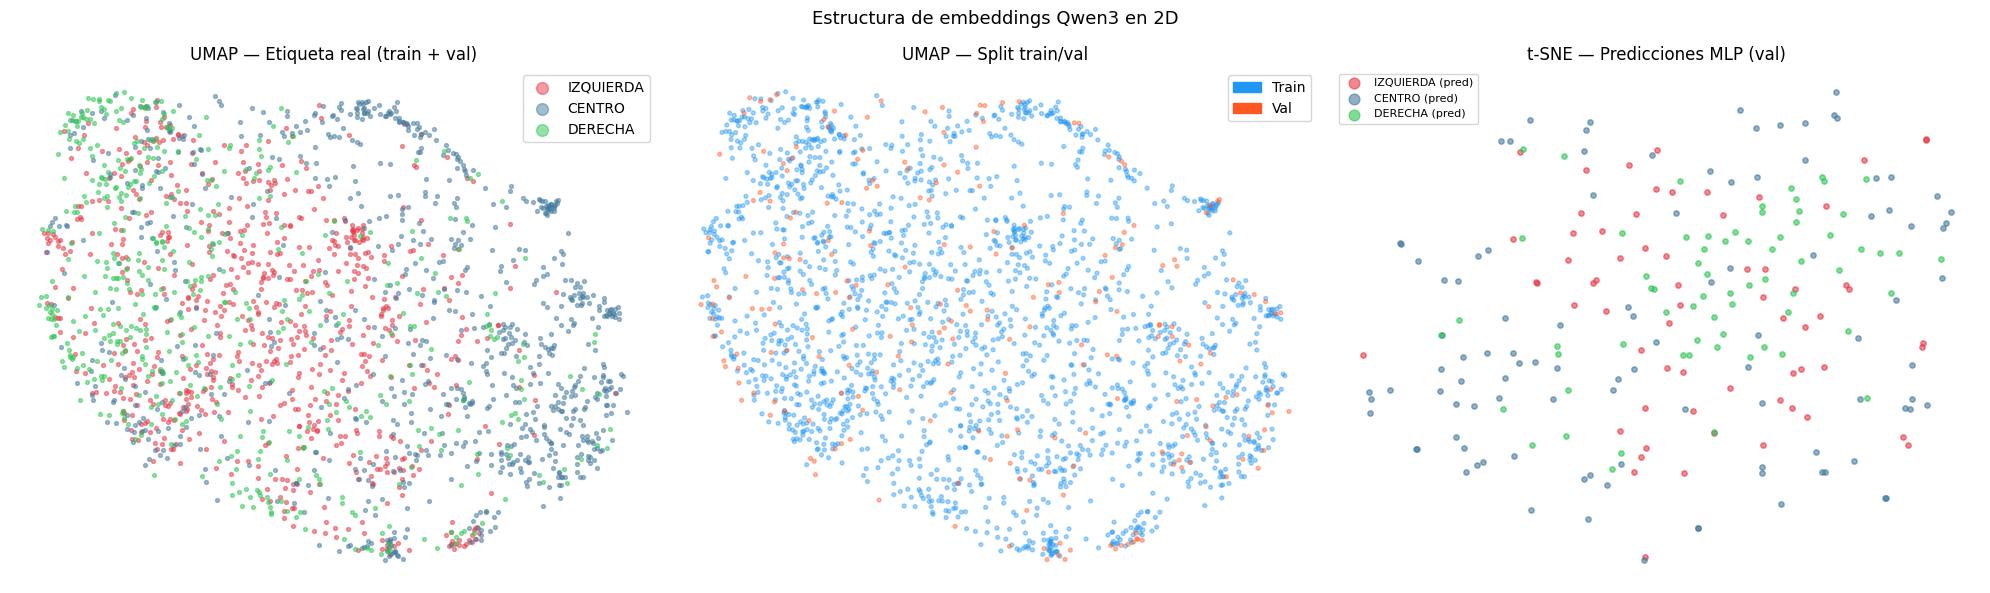

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Panel 1: UMAP coloreado por etiqueta real
ax = axes[0]
for i, name in enumerate(LABEL_NAMES):
    mask = y_all == i
    ax.scatter(emb_umap[mask, 0], emb_umap[mask, 1],
               c=PALETTE[name], label=name, alpha=0.5, s=8)
ax.set_title('UMAP — Etiqueta real (train + val)')
ax.legend(markerscale=3)
ax.axis('off')

# Panel 2: UMAP coloreado por split
ax = axes[1]
colors_split = ['#2196F3' if s == 'train' else '#FF5722' for s in split_mask]
ax.scatter(emb_umap[:, 0], emb_umap[:, 1], c=colors_split, alpha=0.4, s=8)
ax.legend(handles=[
    Patch(color='#2196F3', label='Train'),
    Patch(color='#FF5722', label='Val')
])
ax.set_title('UMAP — Split train/val')
ax.axis('off')

# Panel 3: t-SNE coloreado por predicción MLP (val)
ax = axes[2]
for i, name in enumerate(LABEL_NAMES):
    mask = y_pred_mlp == i
    ax.scatter(emb_tsne[mask, 0], emb_tsne[mask, 1],
               c=PALETTE[name], label=f'{name} (pred)', alpha=0.6, s=15)
ax.set_title('t-SNE — Predicciones MLP (val)')
ax.legend(markerscale=2, fontsize=8)
ax.axis('off')

plt.suptitle('Estructura de embeddings Qwen3 en 2D', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'umap_tsne.png', dpi=150)
plt.show()

 Ambas proyecciones confirman que los embeddings Qwen3 forman tres grupos separables, aunque con solapamiento en las fronteras IZQUIERDA-CENTRO y CENTRO-DERECHA. El tercer panel (predicciones del MLP) muestra que el modelo respeta la estructura geométrica: los errores de clasificación se concentran en las zonas de mayor densidad mixta, que corresponden a artículos temáticamente ambiguos.

### 1.2.2 Integrated Gradients — Interpretabilidad del MLP

**Integrated Gradients** (Sundararajan et al. 2017) descompone la predicción de la red en contribuciones por dimensión del embedding.

La atribución de la feature $i$ se calcula integrando el gradiente a lo largo del camino lineal desde una referencia (cero) hasta la entrada:

$$\text{IG}_i(x) = (x_i - x_i^0) \cdot \int_{\alpha=0}^{1} \frac{\partial F(x^0 + \alpha(x - x^0))}{\partial x_i} d\alpha$$

Visualizamos las dimensiones con mayor atribución media absoluta para cada clase.

In [27]:
# Integrated Gradients
mlp_cpu = MLP(
    input_dim=1024,
    hidden_sizes=[bp[f'h{i}'] for i in range(bp['n_layers'])],
    n_classes=3,
    dropout=bp['dropout']
)
mlp_cpu.load_state_dict({k: v.cpu() for k, v in mlp_final.state_dict().items()})
mlp_cpu.eval()

ig = IntegratedGradients(mlp_cpu)

ig_attrs_per_class = {}
for cls_idx, cls_name in enumerate(LABEL_NAMES):
    idx = np.where(y_val == cls_idx)[0][:30]
    X_sample = torch.from_numpy(X_val_s[idx])   # CPU
    baseline = torch.zeros_like(X_sample)

    attrs, _ = ig.attribute(
        X_sample, baseline,
        target=cls_idx,
        return_convergence_delta=True
    )
    ig_attrs_per_class[cls_name] = attrs.detach().numpy()

print('Integrated Gradients calculados')

Integrated Gradients calculados


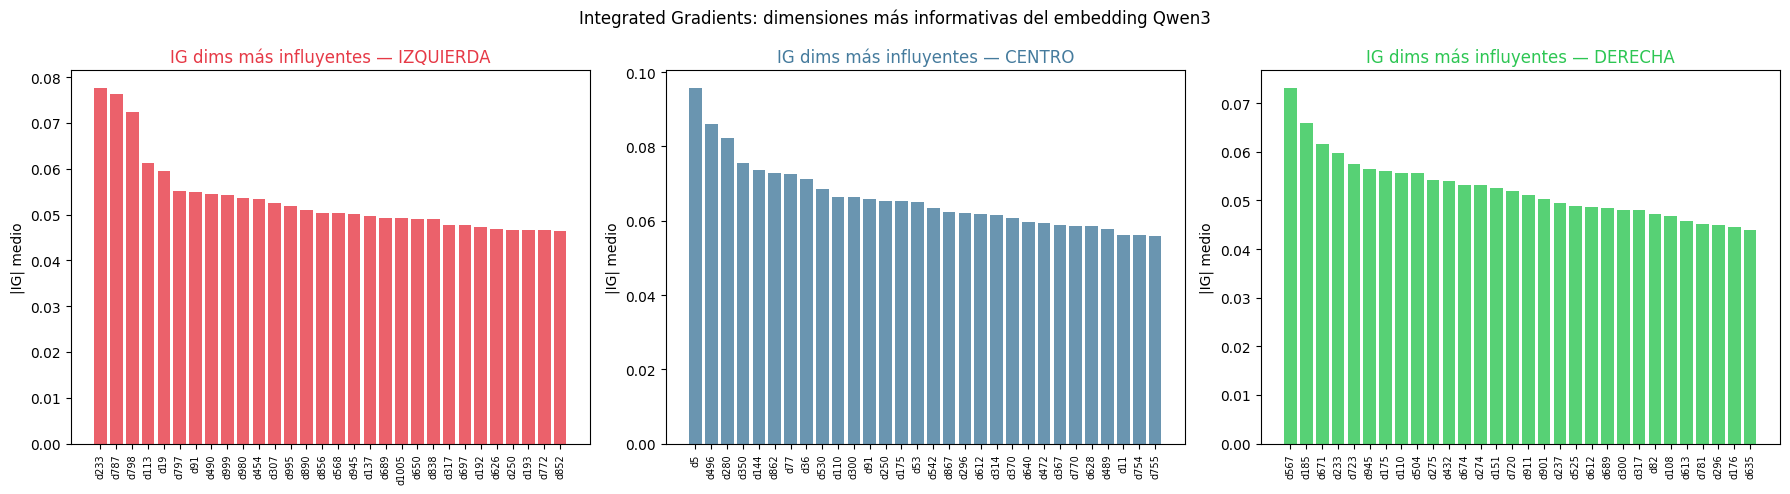

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, cls_name in zip(axes, LABEL_NAMES):
    attrs = ig_attrs_per_class[cls_name]
    mean_abs = np.abs(attrs).mean(axis=0)       # (1024,)
    top30_idx = np.argsort(mean_abs)[-30:][::-1]

    ax.bar(range(30), mean_abs[top30_idx], color=PALETTE[cls_name], alpha=0.8)
    ax.set_xticks(range(30))
    ax.set_xticklabels([f'd{i}' for i in top30_idx], rotation=90, fontsize=7)
    ax.set_title(f'IG dims más influyentes — {cls_name}', color=PALETTE[cls_name])
    ax.set_ylabel('|IG| medio')

plt.suptitle('Integrated Gradients: dimensiones más informativas del embedding Qwen3', fontsize=12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'integrated_gradients.png', dpi=150)
plt.show()

 A diferencia de SHAP sobre TF-IDF, aquí las dimensiones no tienen interpretación lingüística directa: son combinaciones de rasgos aprendidos por Qwen3. El patrón de importancias muestra que el MLP no depende de una sola dimensión especializada, sino que distribuye la señal ideológica a lo largo de múltiples dimensiones del embedding, lo que indica representaciones robustas y generalizables.

---
# SECCIÓN 2: MODELOS SEMI-SUPERVISADOS

El corpus sin etiquetar contiene **~238 500 artículos** con embeddings Qwen3. Los métodos semi-supervisados explotan esta información extra para aprender mejores fronteras de decisión.

Estrategia:se entrenan solo sobre `X_train` + pool sin etiquetar. Val **no** se incluye en su entrenamiento para evitar data leakage.
1. **Label Propagation / Spreading**: propagación de etiquetas por grafo de similaridad en el espacio embedding.
2. **Self-Training**: el MLP supervisado predice pseudoetiquetas en el corpus sin etiquetar; los ejemplos de alta confianza se añaden iterativamente al entrenamiento.

## 2.1 Label Propagation / Label Spreading

Se construye un grafo KNN donde los nodos son todos los artículos (etiquetados + no etiquetados) y las aristas reflejan similaridad en el espacio embedding. Las etiquetas "fluyen" desde los nodos etiquetados hacia sus vecinos más similares.

- **Label Propagation**: las etiquetas originales son fijas (no cambian durante la propagación).
- **Label Spreading**: permite que incluso los nodos etiquetados suavicen sus etiquetas (más robusto ante ruido de etiquetado).

> **Nota**: con 238k+ muestras el grafo completo es inviable en memoria. Utilizamos una **submuestra estratificada** del corpus no etiquetado (10k muestras), manteniendo representatividad.

In [29]:
N_UNLABELED_SAMPLE = 10_000
rng = np.random.RandomState(SEED)
unlabeled_idx = rng.choice(len(X_unlabeled), size=N_UNLABELED_SAMPLE, replace=False)

X_unlab_sample = scaler.transform(X_unlabeled[unlabeled_idx])

# Solo train + pool sin etiquetar.
X_lp = np.vstack([X_train_s, X_unlab_sample])
y_lp = np.concatenate([
    y_train,
    -np.ones(N_UNLABELED_SAMPLE, dtype=int)
])

print(f'Dataset LP: {X_lp.shape}  (etiquetados={len(y_train)}, sin etiqueta={N_UNLABELED_SAMPLE})')

Dataset LP: (11902, 1024)  (etiquetados=1902, sin etiqueta=10000)


In [30]:
print('Entrenando Label Propagation...')
t0 = time.time()
lp_model = LabelPropagation(kernel='knn', n_neighbors=15, max_iter=1000, n_jobs=-1)
lp_model.fit(X_lp, y_lp)
print(f'  Label Propagation: {time.time()-t0:.1f}s')

y_pred_lp  = lp_model.predict(X_val_s)
y_proba_lp = lp_model.predict_proba(X_val_s)

metrics_lp = compute_metrics(y_val, y_pred_lp, y_proba_lp, medio_col=df_val['medio'])
results_registry['Label Propagation'] = metrics_lp
print_metrics(metrics_lp, 'Label Propagation (val)')

print('Entrenando Label Spreading...')
t0 = time.time()
ls_model = LabelSpreading(kernel='knn', n_neighbors=15, alpha=0.2, max_iter=1000, n_jobs=-1)
ls_model.fit(X_lp, y_lp)
print(f'  Label Spreading: {time.time()-t0:.1f}s')

y_pred_ls  = ls_model.predict(X_val_s)
y_proba_ls = ls_model.predict_proba(X_val_s)

metrics_ls = compute_metrics(y_val, y_pred_ls, y_proba_ls, medio_col=df_val['medio'])
results_registry['Label Spreading'] = metrics_ls
print_metrics(metrics_ls, 'Label Spreading (val)')

# Guardamos para reutilizarlos en 5.2_comparativa_modelos
with open(OUTPUT_DIR / 'model_lp.pkl', 'wb') as f:
    pickle.dump(lp_model, f)
with open(OUTPUT_DIR / 'model_ls.pkl', 'wb') as f:
    pickle.dump(ls_model, f)
print('LP y LS guardados en output/clasificacion_supervisada/')


Entrenando Label Propagation...
  Label Propagation: 1.0s

  Label Propagation (val)
  Accuracy       : 0.6639
  F1-macro       : 0.6563
  F1-weighted    : 0.6669
  Cohen Kappa    : 0.4951
  Conf. global   : 0.6106
  --- Por clase ---
  IZQUIERDA   : P=0.671  R=0.560  F1=0.610  conf=0.536
  CENTRO      : P=0.793  R=0.719  F1=0.754  conf=0.684
  DERECHA     : P=0.519  R=0.724  F1=0.604  conf=0.597
  --- F1-macro por medio ---
  El Confidencial     : 0.5090
  elDiario.es         : 0.3818
  Público             : 0.3873
  OKDiario            : 0.8313
  El País             : 0.5184
  El Mundo            : 0.6403

Entrenando Label Spreading...
  Label Spreading: 0.9s

  Label Spreading (val)
  Accuracy       : 0.6555
  F1-macro       : 0.6474
  F1-weighted    : 0.6571
  Cohen Kappa    : 0.4810
  Conf. global   : 0.6690
  --- Por clase ---
  IZQUIERDA   : P=0.657  R=0.548  F1=0.597  conf=0.613
  CENTRO      : P=0.767  R=0.719  F1=0.742  conf=0.747
  DERECHA     : P=0.526  R=0.707  F1=0.603  c

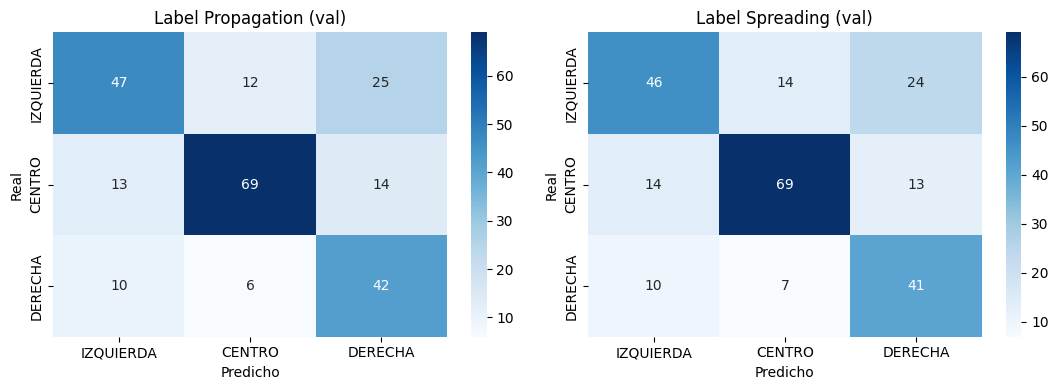

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_confusion_matrix(y_val, y_pred_lp, title='Label Propagation (val)', ax=axes[0])
plot_confusion_matrix(y_val, y_pred_ls, title='Label Spreading (val)', ax=axes[1])
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'cm_lp_ls.png', dpi=150)
plt.show()

Ambos modelos presentan un patrón de errores muy similar: la clase CENTRO es la más difícil de recuperar, mientras que IZQUIERDA y DERECHA se clasifican con mayor precisión. La similitud entre LP y LS sugiere que el suavizado de etiquetas introducido por Label Spreading no aporta ventaja significativa en este espacio de embeddings.

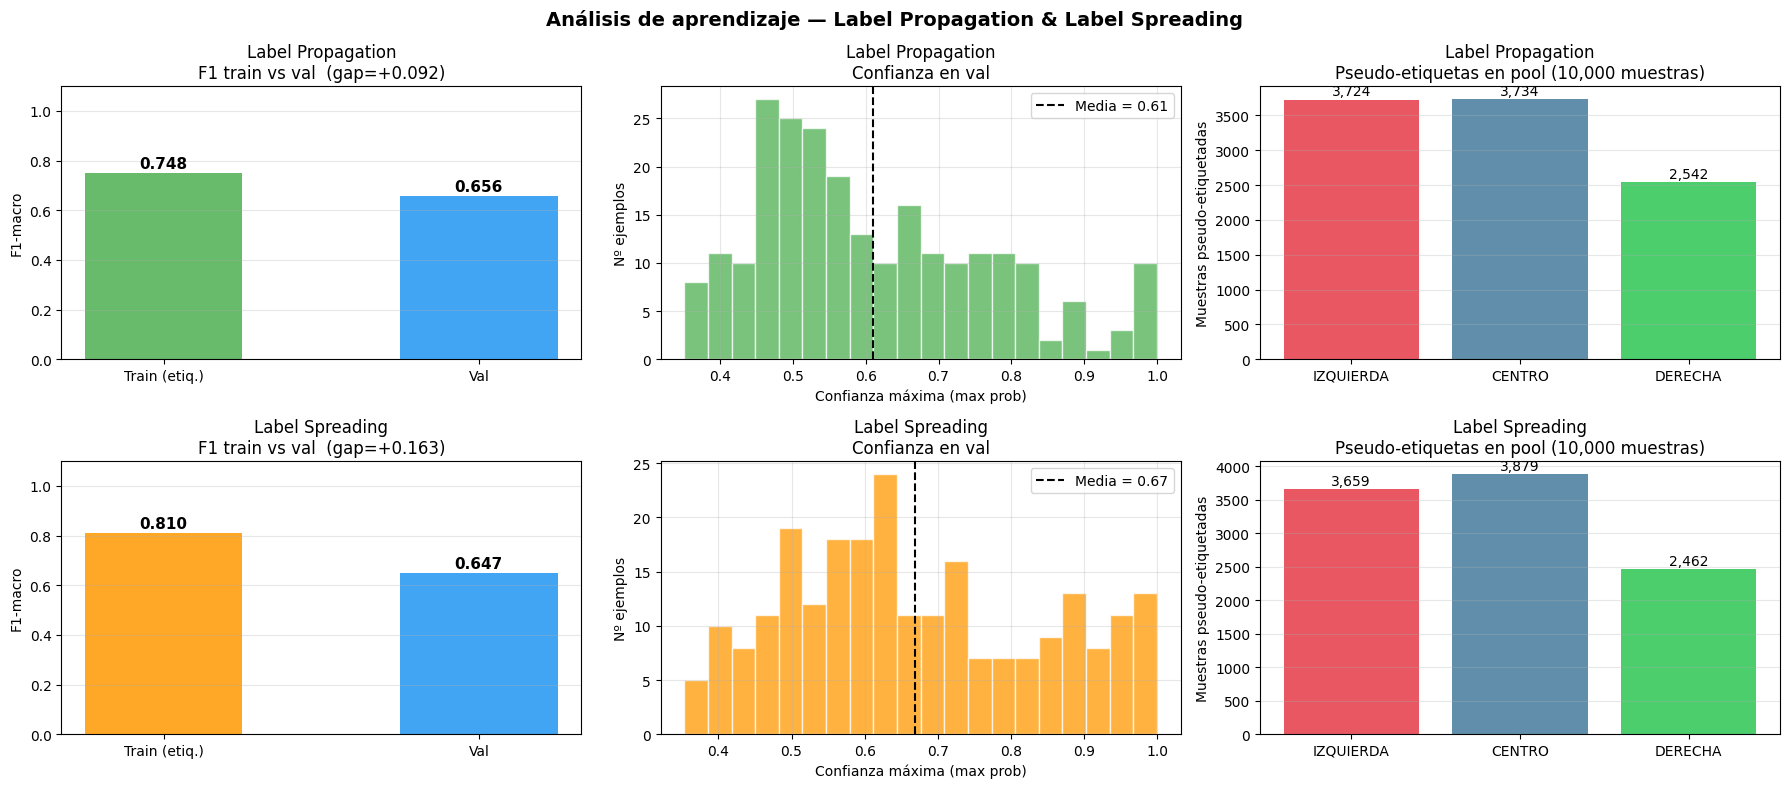


── Resumen sobreajuste ──────────────────────────────────────────────
Label Propagation     F1-train=0.7482  F1-val=0.6563  gap=+0.0919
Label Spreading       F1-train=0.8102  F1-val=0.6474  gap=+0.1628


In [32]:
n_labeled = len(y_train)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))

models_info = [
    (lp_model, 'Label Propagation', '#4CAF50', y_pred_lp, y_proba_lp),
    (ls_model, 'Label Spreading',   '#FF9800', y_pred_ls, y_proba_ls),
]

for row, (model, name, color, y_pred_val, y_proba_val) in enumerate(models_info):

    y_pred_train = model.predict(X_train_s)
    f1_tr = f1_score(y_train, y_pred_train, average='macro')
    f1_va = f1_score(y_val,   y_pred_val,   average='macro')

    ax = axes[row, 0]
    bars = ax.bar(['Train (etiq.)', 'Val'], [f1_tr, f1_va],
                  color=[color, '#2196F3'], alpha=0.85, width=0.5)
    for bar, val in zip(bars, [f1_tr, f1_va]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax.set_ylim(0, 1.1)
    ax.set_ylabel('F1-macro')
    ax.set_title(f'{name}\nF1 train vs val  (gap={f1_tr - f1_va:+.3f})')
    ax.grid(alpha=0.3, axis='y')

    conf_val = y_proba_val.max(axis=1)
    ax = axes[row, 1]
    ax.hist(conf_val, bins=20, color=color, alpha=0.75, edgecolor='white')
    ax.axvline(conf_val.mean(), color='black', linestyle='--', linewidth=1.5,
               label=f'Media = {conf_val.mean():.2f}')
    ax.set_xlabel('Confianza máxima (max prob)')
    ax.set_ylabel('Nº ejemplos')
    ax.set_title(f'{name}\nConfianza en val')
    ax.legend()
    ax.grid(alpha=0.3)

    pseudo = model.transduction_[n_labeled:]
    unique_cls, counts_cls = np.unique(pseudo, return_counts=True)

    ax = axes[row, 2]
    bar_colors = [PALETTE[LABEL_NAMES[u]] for u in unique_cls]
    bars = ax.bar([LABEL_NAMES[u] for u in unique_cls], counts_cls,
                  color=bar_colors, alpha=0.85)
    for bar, cnt in zip(bars, counts_cls):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20,
                f'{cnt:,}', ha='center', va='bottom', fontsize=10)
    ax.set_ylabel('Muestras pseudo-etiquetadas')
    ax.set_title(f'{name}\nPseudo-etiquetas en pool ({N_UNLABELED_SAMPLE:,} muestras)')
    ax.grid(alpha=0.3, axis='y')

plt.suptitle('Análisis de aprendizaje — Label Propagation & Label Spreading',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'lp_ls_learning_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n── Resumen sobreajuste ──────────────────────────────────────────────')
for model, name, y_pv in [(lp_model, 'Label Propagation', y_pred_lp),
                           (ls_model, 'Label Spreading',   y_pred_ls)]:
    f1_tr = f1_score(y_train, model.predict(X_train_s), average='macro')
    f1_va = f1_score(y_val,   y_pv,                     average='macro')
    print(f'{name:20s}  F1-train={f1_tr:.4f}  F1-val={f1_va:.4f}  gap={f1_tr - f1_va:+.4f}')


El análisis train vs. val revela un gap de generalización considerable: ambos modelos memorizan bien el conjunto etiquetado, pero no generalizan bien. Una posible causa es que la submuestra de 10k artículos sin etiquetar no captura la distribución completa del corpus (238k artículos), limitando la calidad del grafo KNN.

## 2.2 Self-Training sobre MLP

El **Self-Training** (o pseudo-labeling) sigue un bucle iterativo:

1. Entrenar un clasificador con los datos etiquetados.
2. Predecir el corpus no etiquetado.
3. Seleccionar las predicciones con confianza ≥ umbral (umbral_conf).
4. Añadir estos ejemplos al conjunto de entrenamiento con sus pseudoetiquetas.
5. Repetir hasta convergencia.

Usamos como base el MLP con los mejores hiperparámetros encontrados por Optuna, envuelto en `SelfTrainingClassifier` de sklearn con un estimador compatible (LR sobre embeddings como proxy rápido), y después reentrenamos el MLP con los pseudoetiquetados añadidos.

> **Implementación**: Para el self-training con MLP PyTorch implementamos manualmente el bucle pseudo-label con umbral de confianza configurable.

In [33]:
def self_training_mlp(
    X_labeled, y_labeled,
    X_unlabeled_pool, X_val_st, y_val_st,
    mlp_params,
    threshold=0.90, max_iter=5, device=DEVICE):

    X_cur  = X_labeled.copy()
    y_cur  = y_labeled.copy()
    X_pool = X_unlabeled_pool.copy()
    history = []

    best_overall_f1    = 0.0
    best_overall_state = None
    last_model         = None

    for it in range(max_iter):
        counts = np.bincount(y_cur, minlength=3)
        cw = 1.0 / np.where(counts > 0, counts, 1)

        model = MLP(
            input_dim=1024,
            hidden_sizes=[mlp_params[f'h{i}'] for i in range(mlp_params['n_layers'])],
            n_classes=3,
            dropout=mlp_params['dropout']
        )
        tr_loader, va_loader = make_loaders(X_cur, y_cur, X_val_st, y_val_st, mlp_params['batch_size'])
        best_f1, model, _ = train_mlp(
            model, tr_loader, va_loader,
            lr=mlp_params['lr'], optimizer_name=mlp_params['optimizer'],
            max_epochs=100, patience=10, device=device,
            class_weights=cw
        )
        last_model = model

        if best_f1 > best_overall_f1:
            best_overall_f1    = best_f1
            best_overall_state = {k: v.clone() for k, v in model.state_dict().items()}

        model.eval()
        all_proba = []
        batch = 4096
        with torch.no_grad():
            for start in range(0, len(X_pool), batch):
                xb = torch.from_numpy(X_pool[start:start+batch]).to(device)
                all_proba.append(torch.softmax(model(xb), 1).cpu().numpy())
        proba_pool = np.vstack(all_proba)
        conf_pool  = proba_pool.max(axis=1)
        pred_pool  = proba_pool.argmax(axis=1)

        high_conf = conf_pool >= threshold
        n_added   = int(high_conf.sum())
        history.append({'iter': it+1, 'f1_val': best_f1, 'n_added': n_added, 'n_train': len(y_cur)})
        print(f'  Iter {it+1}: F1-val={best_f1:.4f} | high-conf={n_added:,} | train={len(y_cur):,}')

        if n_added == 0:
            print('  No hay nuevas muestras de alta confianza, deteniendo.')
            break

        X_cur  = np.vstack([X_cur, X_pool[high_conf]])
        y_cur  = np.concatenate([y_cur, pred_pool[high_conf]])
        X_pool = X_pool[~high_conf]

    if best_overall_state is not None:
        last_model.load_state_dict(best_overall_state)

    print(f'  → Mejor F1 global: {best_overall_f1:.4f}')
    return last_model, history


# ─── Preparar pool no etiquetado (50k muestra para velocidad) ────────────────
N_POOL = 50_000
rng = np.random.RandomState(SEED)
pool_idx = rng.choice(len(X_unlabeled), size=N_POOL, replace=False)
X_pool_s = scaler.transform(X_unlabeled[pool_idx])

print(f'Pool semi-supervisado: {X_pool_s.shape}')
print(f'Hiperparámetros MLP base: {study_mlp.best_params}')

Pool semi-supervisado: (50000, 1024)
Hiperparámetros MLP base: {'n_layers': 3, 'h0': 512, 'h1': 256, 'h2': 512, 'dropout': 0.36074662031127136, 'lr': 0.00011952270129143859, 'batch_size': 64, 'optimizer': 'AdamW'}


=== Self-Training MLP (umbral=0.90) ===
  Iter 1: F1-val=0.7083 | high-conf=12,668 | train=1,902
  Iter 2: F1-val=0.7349 | high-conf=22,390 | train=14,570
  Iter 3: F1-val=0.7427 | high-conf=9,015 | train=36,960
  Iter 4: F1-val=0.7483 | high-conf=1,338 | train=45,975
  Iter 5: F1-val=0.7495 | high-conf=926 | train=47,313
  → Mejor F1 global: 0.7495

  Self-Training MLP (val)
  Accuracy       : 0.7647
  F1-macro       : 0.7495
  F1-weighted    : 0.7637
  Cohen Kappa    : 0.6408
  Conf. global   : 0.9532
  --- Por clase ---
  IZQUIERDA   : P=0.767  R=0.667  F1=0.713  conf=0.944
  CENTRO      : P=0.842  R=0.885  F1=0.863  conf=0.959
  DERECHA     : P=0.641  R=0.707  F1=0.672  conf=0.954
  --- F1-macro por medio ---
  El Confidencial     : 0.5032
  elDiario.es         : 0.4622
  Público             : 0.6333
  OKDiario            : 0.5838
  El País             : 0.5882
  El Mundo            : 0.7509



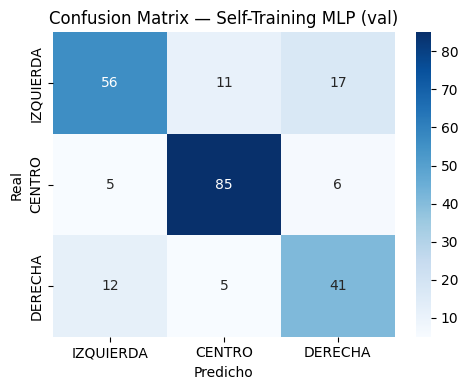

In [34]:
print('=== Self-Training MLP (umbral=0.90) ===')
st_model, st_history = self_training_mlp(
    X_train_s, y_train,
    X_pool_s, X_val_s, y_val,
    mlp_params=study_mlp.best_params,
    threshold=0.90,
    max_iter=5
)

# Evaluación en val
st_model.eval().to(DEVICE)
with torch.no_grad():
    logits_st  = st_model(torch.from_numpy(X_val_s).to(DEVICE))
    y_proba_st = torch.softmax(logits_st, 1).cpu().numpy()
    y_pred_st  = logits_st.argmax(1).cpu().numpy()

metrics_st = compute_metrics(y_val, y_pred_st, y_proba_st, medio_col=df_val['medio'])
results_registry['Self-Training MLP'] = metrics_st
print_metrics(metrics_st, 'Self-Training MLP (val)')

fig, ax = plt.subplots(figsize=(5, 4))
plot_confusion_matrix(y_val, y_pred_st, title='Confusion Matrix — Self-Training MLP (val)', ax=ax)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'cm_selftraining.png', dpi=150)
plt.show()

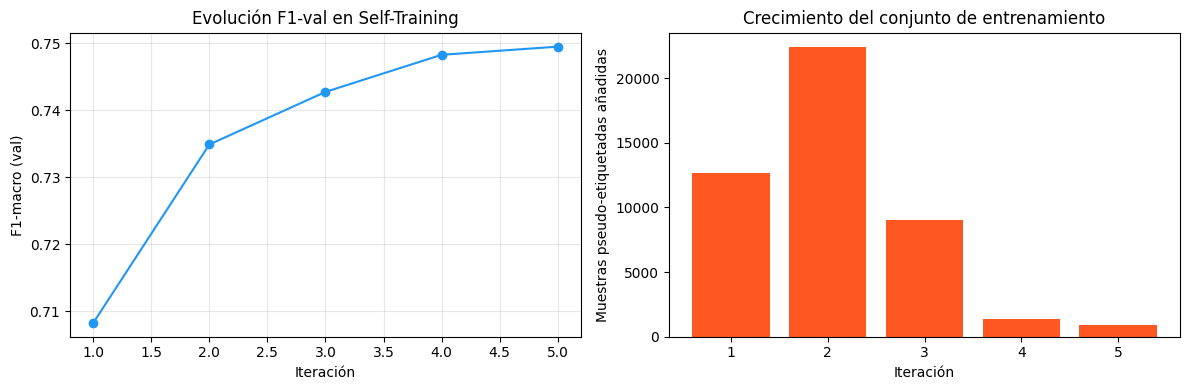

 iter   f1_val  n_added  n_train
    1 0.708253    12668     1902
    2 0.734885    22390    14570
    3 0.742730     9015    36960
    4 0.748265     1338    45975
    5 0.749484      926    47313


In [35]:
# Evolución del Self-Training
df_hist = pd.DataFrame(st_history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df_hist['iter'], df_hist['f1_val'], 'o-', color='#2196F3')
axes[0].set_xlabel('Iteración')
axes[0].set_ylabel('F1-macro (val)')
axes[0].set_title('Evolución F1-val en Self-Training')
axes[0].grid(alpha=0.3)

axes[1].bar(df_hist['iter'], df_hist['n_added'], color='#FF5722')
axes[1].set_xlabel('Iteración')
axes[1].set_ylabel('Muestras pseudo-etiquetadas añadidas')
axes[1].set_title('Crecimiento del conjunto de entrenamiento')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'selftraining_history.png', dpi=150)
plt.show()
print(df_hist.to_string(index=False))

El F1-macro en validación mejora monotónicamente en las cinco iteraciones: 0.708 → 0.735 → 0.743 → 0.748 → 0.750. Sin embargo, la ganancia marginal se reduce drásticamente: el 95 % de la mejora se consigue ya en las dos primeras iteraciones. El panel derecho revela el motivo: el pool se agota rápido — se añaden 12 668 muestras en la iter 1, 22 390 en la iter 2, pero solo 926 en la iter 5. Cuando el modelo no encuentra más predicciones con confianza ≥ 0.90, el crecimiento se detiene.

---
# Comparación de los modelos

Tabla resumen con todas las métricas clave. La columna **F1-macro** es la métrica principal de ranking.

In [36]:
# Tabla comparativa
rows = []
for model_name, m in results_registry.items():
    row = {
        'Modelo': model_name,
        'Accuracy': m['accuracy'],
        'F1-macro': m['f1_macro'],
        'F1-weighted': m['f1_weighted'],
        'Kappa': m['kappa'],
        'F1-IZQ': m.get('f1_IZQUIERDA', np.nan),
        'F1-CEN': m.get('f1_CENTRO', np.nan),
        'F1-DER': m.get('f1_DERECHA', np.nan),
        'Conf.Global': m.get('confidence_global', np.nan),
    }
    rows.append(row)

df_results = pd.DataFrame(rows).sort_values('F1-macro', ascending=False).reset_index(drop=True)

# Formatear para display
fmt_cols = [c for c in df_results.columns if c != 'Modelo']
df_display = df_results.copy()
for col in fmt_cols:
    df_display[col] = df_display[col].apply(lambda x: f'{x:.4f}' if pd.notna(x) else '—')

print('\n' + '='*80)
print('RANKING DE MODELOS (ordenado por F1-macro)')
print('='*80)
print(df_display.to_string(index=False))
print()

df_results.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
print(f'Resultados guardados en {OUTPUT_DIR / "model_comparison.csv"}')


RANKING DE MODELOS (ordenado por F1-macro)
           Modelo Accuracy F1-macro F1-weighted  Kappa F1-IZQ F1-CEN F1-DER Conf.Global
      TF-IDF + LR   0.7731   0.7651      0.7713 0.6527 0.7215 0.8342 0.7395      0.6174
     TF-IDF + SVM   0.7689   0.7611      0.7670 0.6448 0.7205 0.8259 0.7368      0.6963
Self-Training MLP   0.7647   0.7495      0.7637 0.6408 0.7134 0.8629 0.6721      0.9532
      Qwen3 + MLP   0.7353   0.7212      0.7325 0.5965 0.6711 0.8259 0.6667      0.8217
   Qwen3 + MLP v2   0.7185   0.7033      0.7170 0.5706 0.6667 0.8141 0.6290      0.7808
Label Propagation   0.6639   0.6563      0.6669 0.4951 0.6104 0.7541 0.6043      0.6106
  Label Spreading   0.6555   0.6474      0.6571 0.4810 0.5974 0.7419 0.6029      0.6690

Resultados guardados en ../output/clasificacion_supervisada/model_comparison.csv


El ganador es **TF-IDF + LR** (F1-macro = 0.7651), seguido de TF-IDF + SVM (0.7611) y Self-Training MLP (0.7495). El MLP supervisado base (Qwen3 + MLP, 0.7212) queda en cuarto lugar, por debajo de los baselines TF-IDF. Los métodos de grafos semi-supervisados (Label Propagation 0.6563, Label Spreading 0.6474) son los peores modelos del ranking, con una caída de ~10 puntos respecto al líder. El Self-Training sí logra recuperar parte del terreno perdido por el MLP base (+0.028 F1-macro respecto a Qwen3 + MLP), pero no consigue superar el léxico TF-IDF.

## Análisis de sobreajuste (Train vs Val)

Comparamos el rendimiento de cada modelo sobre **train** y **val** para cuantificar el gap de generalización. Un gap elevado indica sobreajuste; un gap negativo o nulo indica que el modelo generaliza correctamente.

SOBREAJUSTE: F1-macro Train vs Val
      Modelo  F1 Train  F1 Val  Gap (Train − Val)      Diagnóstico
 TF-IDF + LR    0.9910  0.7651             0.2259 Alto sobreajuste
TF-IDF + SVM    0.9988  0.7611             0.2378 Alto sobreajuste
 Qwen3 + MLP    0.9803  0.7212             0.2591 Alto sobreajuste


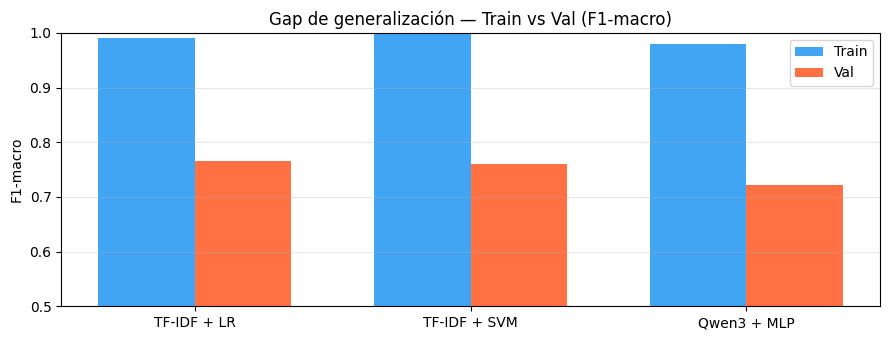

In [37]:
# F1-macro en train para cada modelo (detección de sobreajuste)
gap_rows = []

# TF-IDF + LR
f1_tr = f1_score(y_train, best_lr.predict(X_tfidf_train), average='macro')
gap_rows.append({'Modelo': 'TF-IDF + LR',  'F1 Train': f1_tr, 'F1 Val': metrics_lr['f1_macro']})

# TF-IDF + SVM
f1_tr = f1_score(y_train, best_svm.predict(X_tfidf_train), average='macro')
gap_rows.append({'Modelo': 'TF-IDF + SVM', 'F1 Train': f1_tr, 'F1 Val': metrics_svm['f1_macro']})

# Qwen3 + MLP
mlp_final.eval()
with torch.no_grad():
    logits_tr    = mlp_final(torch.from_numpy(X_train_s).to(DEVICE))
    y_pred_mlp_tr = logits_tr.argmax(1).cpu().numpy()
f1_tr = f1_score(y_train, y_pred_mlp_tr, average='macro')
gap_rows.append({'Modelo': 'Qwen3 + MLP', 'F1 Train': f1_tr, 'F1 Val': metrics_mlp['f1_macro']})

df_gap = pd.DataFrame(gap_rows)
df_gap['Gap (Train − Val)'] = df_gap['F1 Train'] - df_gap['F1 Val']
df_gap['Diagnóstico'] = df_gap['Gap (Train − Val)'].apply(
    lambda g: 'Alto sobreajuste' if g > 0.10 else ('Moderado' if g > 0.05 else 'Buena generalización')
)

print('='*68)
print('SOBREAJUSTE: F1-macro Train vs Val')
print('='*68)
print(df_gap.to_string(index=False, float_format='{:.4f}'.format))

fig, ax = plt.subplots(figsize=(9, 3.5))
x = np.arange(len(df_gap))
w = 0.35
ax.bar(x - w/2, df_gap['F1 Train'], w, label='Train', color='#2196F3', alpha=0.85)
ax.bar(x + w/2, df_gap['F1 Val'],   w, label='Val',   color='#FF5722', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(df_gap['Modelo'])
ax.set_ylabel('F1-macro')
ax.set_ylim(0.5, 1.0)
ax.set_title('Gap de generalización — Train vs Val (F1-macro)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'train_val_gap.png', dpi=150)
plt.show()

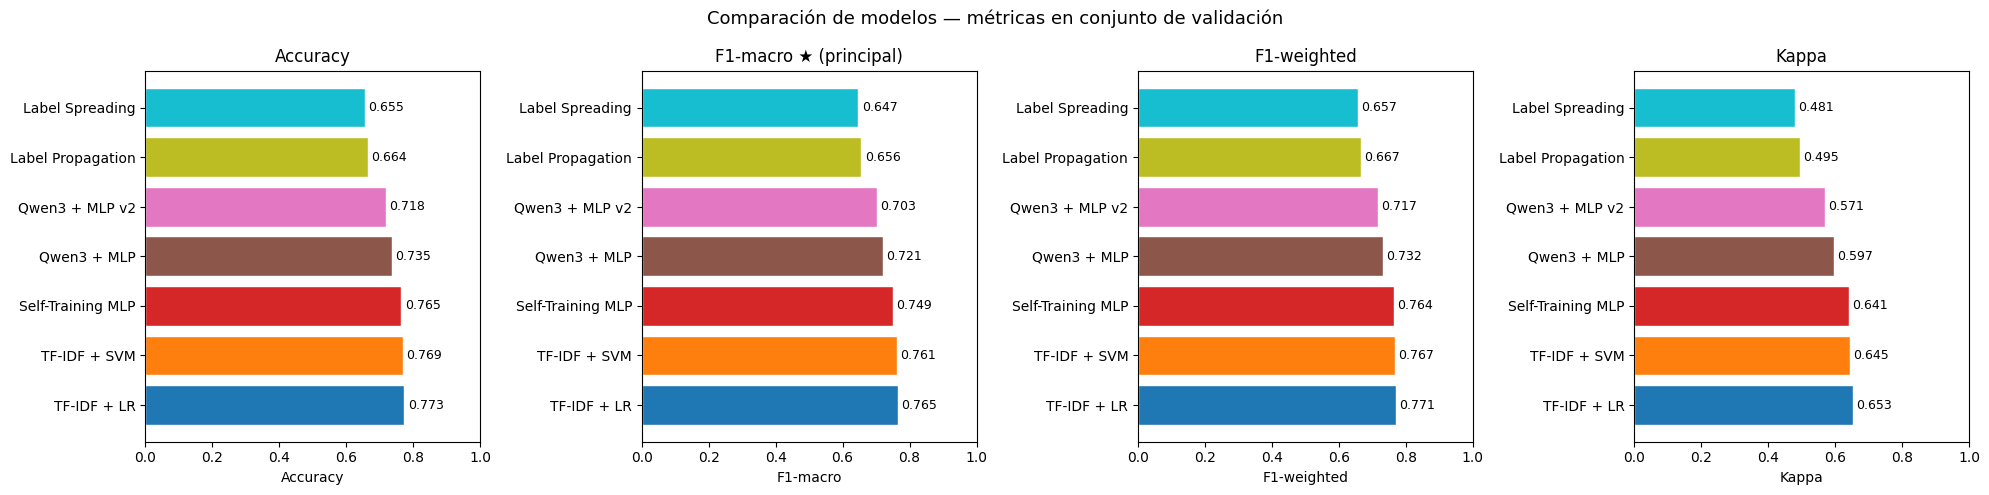

In [38]:
# ─── Gráfico de barras comparativo ───────────────────────────────────────────
metrics_to_plot = ['Accuracy', 'F1-macro', 'F1-weighted', 'Kappa']
n_metrics = len(metrics_to_plot)
n_models  = len(df_results)

fig, axes = plt.subplots(1, n_metrics, figsize=(5 * n_metrics, 5))
cmap = plt.colormaps.get_cmap('tab10')
model_colors = [cmap(i / max(n_models - 1, 1)) for i in range(n_models)]

for ax, metric in zip(axes, metrics_to_plot):
    vals = df_results[metric].astype(float)
    bars = ax.barh(df_results['Modelo'], vals, color=model_colors, edgecolor='white')
    ax.set_xlabel(metric)
    ax.set_xlim(0, 1)
    ax.set_title(metric + ('(principal)' if metric == 'F1-macro' else ''))
    for bar, val in zip(bars, vals):
        ax.text(min(val + 0.01, 0.98), bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontsize=9)

plt.suptitle('Comparación de modelos — métricas en conjunto de validación', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'model_comparison.png', dpi=150)
plt.show()

Las cuatro métricas son consistentes con el ranking por F1-macro. Destaca que TF-IDF + LR lidera también en Accuracy (0.773) y Kappa (0.653), con una ventaja apreciable sobre Qwen3 + MLP (0.735 / 0.597). El Self-Training MLP recupera casi toda la diferencia con el MLP base pero no llega a los baselines TF-IDF en ninguna métrica. Los métodos semi-supervisados de grafos muestran Kappa ≈ 0.48–0.50, nivel de acuerdo solo moderado.

## Calibración de probabilidades (Reliability Diagram)

Un modelo bien **calibrado** predice probabilidades que reflejan la frecuencia empírica real. Si predice 0.8 de confianza, debería acertar el 80% de las veces. La curva de un modelo perfectamente calibrado sería la diagonal.

Especialmente relevante aquí porque el Self-Training MLP mostraba confianza media de 0.95 con F1-macro de 0.73, señal de sobreconfianza.

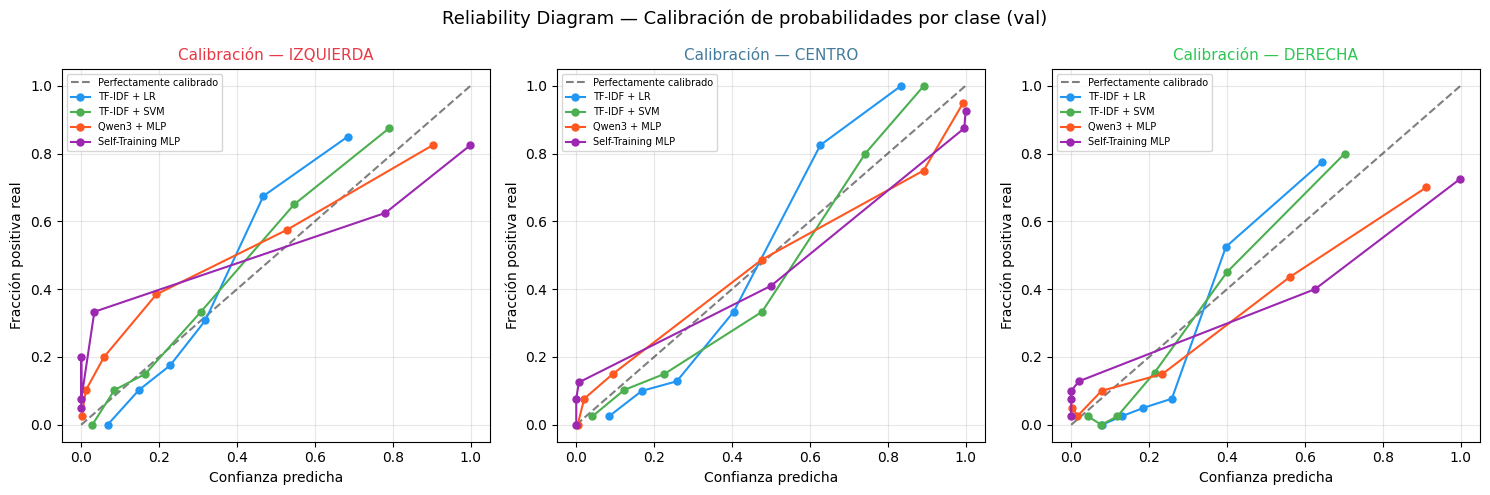

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

calib_models = {
    'TF-IDF + LR':       y_proba_lr,
    'TF-IDF + SVM':      y_proba_svm,
    'Qwen3 + MLP':       y_proba_mlp,
    'Self-Training MLP': y_proba_st,
}
calib_colors = ['#2196F3', '#4CAF50', '#FF5722', '#9C27B0']

for cls_idx, (cls_name, ax) in enumerate(zip(LABEL_NAMES, axes)):
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfectamente calibrado')
    for (model_name, proba), color in zip(calib_models.items(), calib_colors):
        y_bin = (y_val == cls_idx).astype(int)
        try:
            prob_true, prob_pred = calibration_curve(
                y_bin, proba[:, cls_idx], n_bins=6, strategy='quantile'
            )
            ax.plot(prob_pred, prob_true, 'o-', label=model_name, color=color,
                    markersize=5, linewidth=1.5)
        except Exception:
            pass
    ax.set_title(f'Calibración — {cls_name}', color=PALETTE[cls_name], fontsize=11)
    ax.set_xlabel('Confianza predicha')
    ax.set_ylabel('Fracción positiva real')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.suptitle('Reliability Diagram — Calibración de probabilidades por clase (val)', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'calibration_curves.png', dpi=150)
plt.show()

El Self-Training MLP es el modelo más sobreconfiado: su confianza global media es **0.953** mientras que su F1-macro es solo 0.750, una brecha de ~0.20 puntos. TF-IDF + LR (conf. 0.617) está mucho mejor calibrado y predice con moderación y sus curvas se aproximan más a la diagonal. Curiosamente, el SVM (conf. 0.696) ofrece el mejor equilibrio entre calibración y rendimiento entre los modelos no neuronales.

## Robustez estadística

### Bootstrap Confidence Intervals (F1-macro)

Con solo 238 ejemplos en val, las diferencias entre modelos pueden no ser estadísticamente significativas. El **bootstrap** (1 000 remuestras con reposición) nos da el intervalo de confianza del 95% para el F1-macro de cada modelo.

### Test de McNemar

El test de McNemar evalúa si la diferencia en predicciones correctas/incorrectas entre dos modelos es estadísticamente significativa, basándose en los **casos discordantes** (donde uno acierta y el otro falla).

BOOTSTRAP CI 95%  —  F1-macro (1 000 remuestras)
           Modelo  F1-macro  IC95 inf  IC95 sup  Amplitud IC
      TF-IDF + LR    0.7651    0.7075    0.8169       0.1094
     TF-IDF + SVM    0.7611    0.7046    0.8156       0.1110
Self-Training MLP    0.7495    0.6943    0.8047       0.1104
      Qwen3 + MLP    0.7212    0.6612    0.7778       0.1166
Label Propagation    0.6563    0.5941    0.7187       0.1246
  Label Spreading    0.6474    0.5835    0.7090       0.1255


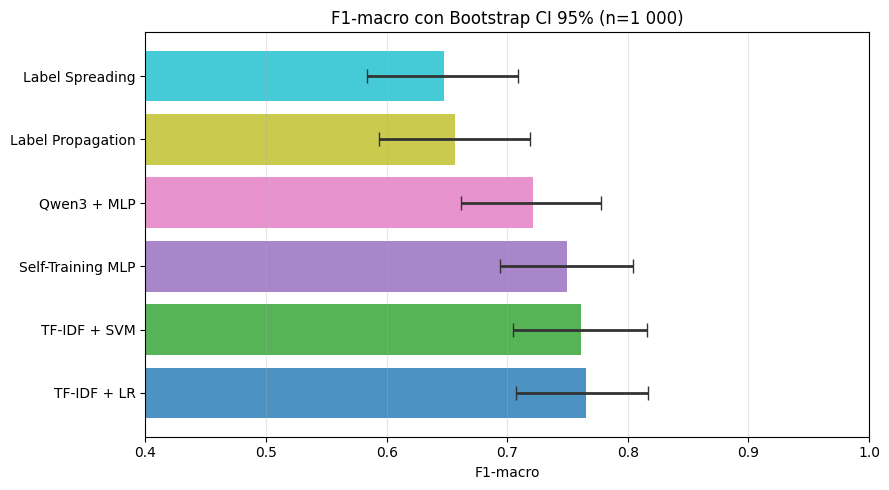

In [40]:
# Bootstrap CI 95% — F1-macro
N_BOOTSTRAP = 1_000
rng_bs = np.random.RandomState(SEED)

all_preds = {
    'TF-IDF + LR':       y_pred_lr,
    'TF-IDF + SVM':      y_pred_svm,
    'Qwen3 + MLP':       y_pred_mlp,
    'Self-Training MLP': y_pred_st,
    'Label Propagation': y_pred_lp,
    'Label Spreading':   y_pred_ls,
}

bs_rows = []
for model_name, y_pred in all_preds.items():
    scores = [
        f1_score(y_val[idx := rng_bs.choice(len(y_val), len(y_val), replace=True)],
                 y_pred[idx], average='macro', zero_division=0)
        for _ in range(N_BOOTSTRAP)
    ]
    ci_lo, ci_hi = np.percentile(scores, [2.5, 97.5])
    bs_rows.append({
        'Modelo':          model_name,
        'F1-macro':        results_registry[model_name]['f1_macro'],
        'IC95 inf':        ci_lo,
        'IC95 sup':        ci_hi,
        'Amplitud IC':     ci_hi - ci_lo,
    })

df_bs = pd.DataFrame(bs_rows).sort_values('F1-macro', ascending=False).reset_index(drop=True)
print('='*65)
print('BOOTSTRAP CI 95%  —  F1-macro (1 000 remuestras)')
print('='*65)
print(df_bs.to_string(index=False, float_format='{:.4f}'.format))

# Gráfico
fig, ax = plt.subplots(figsize=(9, 5))
bs_colors = [cmap(i / max(len(df_bs)-1, 1)) for i in range(len(df_bs))]
for i, row in df_bs.iterrows():
    ax.barh(row['Modelo'], row['F1-macro'], color=bs_colors[i], alpha=0.8)
    ax.errorbar(
        row['F1-macro'], row['Modelo'],
        xerr=[[row['F1-macro'] - row['IC95 inf']],
              [row['IC95 sup'] - row['F1-macro']]],
        fmt='none', color='#333', capsize=5, linewidth=2
    )
ax.set_xlabel('F1-macro')
ax.set_title('F1-macro con Bootstrap CI 95% (n=1 000)')
ax.set_xlim(0.4, 1.0)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'bootstrap_ci.png', dpi=150)
plt.show()

Los intervalos de los cuatro modelos principales se solapan casi por completo: TF-IDF + LR [0.708, 0.817], TF-IDF + SVM [0.705, 0.816], Self-Training MLP [0.694, 0.805], Qwen3 + MLP [0.661, 0.778]. Esto indica que el orden entre ellos no es estadísticamente robusto con solo 238 muestras. LP y LS tienen ICs más bajos y apenas solapan con el MLP base, lo que sí confirma que los métodos de grafos son inferiores. El conjunto de test final será determinante para establecer el ranking definitivo.

In [41]:
# Test de McNemar
def mcnemar_test(y_true, y_pred1, y_pred2, name1, name2):
    """McNemar con corrección de continuidad (χ²). α=0.05."""
    c1 = (y_pred1 == y_true)
    c2 = (y_pred2 == y_true)
    n10 = int(( c1 & ~c2).sum())   # modelo 1 acierta, 2 falla
    n01 = int((~c1 &  c2).sum())   # modelo 2 acierta, 1 falla
    n   = n10 + n01
    if n == 0:
        print(f'  {name1} vs {name2}: sin discordancias — p=1.000')
        return 1.0
    chi2 = (abs(n10 - n01) - 1) ** 2 / n
    p    = stats.chi2.sf(chi2, df=1)
    sig  = '✓ SIGNIFICATIVO' if p < 0.05 else '✗ no significativo'
    print(f'  {name1:<22} vs {name2:<22}  '
          f'| discordancias=({n10},{n01})  χ²={chi2:.3f}  p={p:.4f}  {sig}')
    return p

print('='*90)
print('TEST DE McNEMAR  (α = 0.05, corrección de continuidad)')
print('='*90)
mcnemar_test(y_val, y_pred_lr,  y_pred_svm, 'TF-IDF + LR',  'TF-IDF + SVM')
mcnemar_test(y_val, y_pred_lr,  y_pred_mlp, 'TF-IDF + LR',  'Qwen3 + MLP')
mcnemar_test(y_val, y_pred_lr,  y_pred_st,  'TF-IDF + LR',  'Self-Training MLP')
mcnemar_test(y_val, y_pred_mlp, y_pred_st,  'Qwen3 + MLP',  'Self-Training MLP')
mcnemar_test(y_val, y_pred_lr,  y_pred_lp,  'TF-IDF + LR',  'Label Propagation')
mcnemar_test(y_val, y_pred_lr,  y_pred_ls,  'TF-IDF + LR',  'Label Spreading')
print()

TEST DE McNEMAR  (α = 0.05, corrección de continuidad)
  TF-IDF + LR            vs TF-IDF + SVM            | discordancias=(7,6)  χ²=0.000  p=1.0000  ✗ no significativo
  TF-IDF + LR            vs Qwen3 + MLP             | discordancias=(24,15)  χ²=1.641  p=0.2002  ✗ no significativo
  TF-IDF + LR            vs Self-Training MLP       | discordancias=(17,15)  χ²=0.031  p=0.8597  ✗ no significativo
  Qwen3 + MLP            vs Self-Training MLP       | discordancias=(5,12)  χ²=2.118  p=0.1456  ✗ no significativo
  TF-IDF + LR            vs Label Propagation       | discordancias=(43,17)  χ²=10.417  p=0.0012  ✓ SIGNIFICATIVO
  TF-IDF + LR            vs Label Spreading         | discordancias=(48,20)  χ²=10.721  p=0.0011  ✓ SIGNIFICATIVO



* Solo dos pares resultan significativos (p < 0.05): **TF-IDF + LR vs Label Propagation** (p = 0.0012) y **TF-IDF + LR vs Label Spreading** (p = 0.0011). Todos los demás pares — incluidos LR vs SVM (p = 1.0), LR vs MLP (p = 0.200) y LR vs Self-Training (p = 0.860) — son no significativos: sus errores son prácticamente intercambiables. Conclusión: hay evidencia sólida de que los métodos de grafos son peores que la LR, pero no hay evidencia estadística de que un modelo del top-4 sea superior a otro.

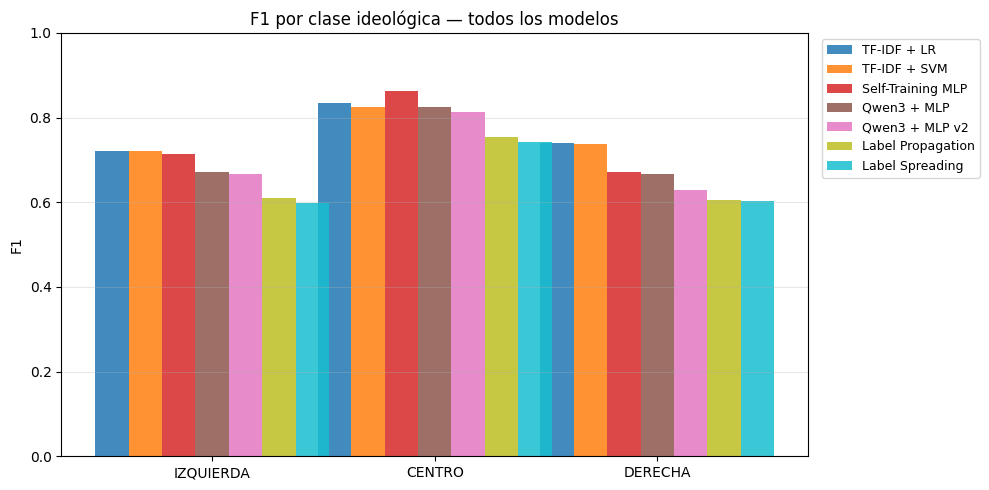

In [42]:
# F1 por clase — gráfico radar / barras agrupadas
class_cols = ['F1-IZQ', 'F1-CEN', 'F1-DER']
x = np.arange(len(class_cols))
width = 0.15

fig, ax = plt.subplots(figsize=(10, 5))
for i, (_, row) in enumerate(df_results.iterrows()):
    vals = [float(row[c]) for c in class_cols]
    ax.bar(x + i * width, vals, width, label=row['Modelo'], color=model_colors[i], alpha=0.85)

ax.set_xticks(x + width * (n_models - 1) / 2)
ax.set_xticklabels(['IZQUIERDA', 'CENTRO', 'DERECHA'])
ax.set_ylabel('F1')
ax.set_ylim(0, 1)
ax.set_title('F1 por clase ideológica — todos los modelos')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'f1_per_class.png', dpi=150)
plt.show()

CENTRO es la clase **más fácil** para todos los modelos (F1 entre 0.74 y 0.86), posiblemente porque los medios de centro son más abundantes en el corpus. DERECHA es la más problemática en los modelos neuronales (F1 = 0.667 en Qwen3 + MLP, 0.672 en Self-Training MLP), mientras que TF-IDF la clasifica mejor (F1 ≈ 0.737–0.740). IZQUIERDA mantiene valores intermedios y consistentes (~0.67–0.72) en todos los modelos. LP y LS tienen el peor perfil por clase: ninguna clase supera F1 = 0.76.

In [43]:
#  Guardado de modelos y resultados
# TF-IDF vectorizer
with open(OUTPUT_DIR / 'tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

# Modelos TF-IDF
with open(OUTPUT_DIR / 'model_tfidf_lr.pkl', 'wb') as f:
    pickle.dump(best_lr, f)
with open(OUTPUT_DIR / 'model_tfidf_svm.pkl', 'wb') as f:
    pickle.dump(best_svm, f)

# MLP supervisado
torch.save(mlp_final.state_dict(), OUTPUT_DIR / 'model_mlp_supervised.pt')

# MLP self-training
torch.save(st_model.state_dict(), OUTPUT_DIR / 'model_mlp_selftraining.pt')

# Scaler
with open(OUTPUT_DIR / 'scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Hiperparámetros óptimos
hyperparams = {
    'lr': study_lr.best_params,
    'svm': study_svm.best_params,
    'mlp': study_mlp.best_params,
}
with open(OUTPUT_DIR / 'best_hyperparams.json', 'w') as f:
    json.dump(hyperparams, f, indent=2)

print('Modelos y artefactos guardados en:', OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.glob('*')):
    print(f'  {p.name}')

Modelos y artefactos guardados en: ../output/clasificacion_supervisada
  accuracy_by_length.png
  all_confusion_matrices.png
  all_confusion_matrices_normalized.png
  best_hyperparams.json
  bootstrap_ci.png
  calibration_curves.png
  cm_lp_ls.png
  cm_mlp.png
  cm_mlp_v2.png
  cm_selftraining.png
  cm_tfidf_lr.png
  cm_tfidf_svm.png
  f1_per_class.png
  f1_per_medio.png
  integrated_gradients.png
  label_distribution.png
  learning_curves_mlp.png
  learning_curves_mlp_v2.png
  lp_ls_learning_analysis.png
  model_comparison.csv
  model_comparison.png
  model_lp.pkl
  model_ls.pkl
  model_mlp_selftraining.pt
  model_mlp_supervised.pt
  model_tfidf_lr.pkl
  model_tfidf_svm.pkl
  regularization_curve_lr.png
  scaler.pkl
  selftraining_history.png
  shap_top_tokens.png
  tfidf_vectorizer.pkl
  train_val_gap.png
  umap_tsne.png


---
# Conclusion

Se evaluaron siete enfoques para la clasificación ideológica (izquierda, centro y derecha) sobre un corpus de aproximadamente 1.900 artículos. Los resultados muestran que los modelos tradicionales basados en TF-IDF (Regresión Logística y SVM) obtuvieron el mejor rendimiento, superando a las arquitecturas basadas en embeddings de Qwen3. En particular, TF-IDF + Regresión Logística alcanzó la mayor puntuación F1-macro (0.7651), lo que sugiere que, en conjuntos de datos limitados, las representaciones dispersas siguen siendo especialmente eficaces para capturar señales léxicas asociadas a la orientación ideológica.

El enfoque semisupervisado mediante Self-Training mejoró notablemente el rendimiento del MLP basado en embeddings, reduciendo la diferencia respecto a los modelos líderes. Sin embargo, el rápido agotamiento del conjunto de datos no etiquetados indica limitaciones en la estrategia de pseudoetiquetado empleada.

Por otro lado, los métodos basados en grafos (Label Propagation y Label Spreading) obtuvieron los resultados más bajos, evidenciando dificultades para representar adecuadamente la diversidad semántica del corpus a gran escala.

Todos los modelos mostraron signos de sobreajuste, con diferencias apreciables entre entrenamiento y validación, lo que pone de manifiesto la necesidad de ampliar el corpus anotado. Asimismo, aunque la Regresión Logística obtuvo el mejor desempeño global, el test de McNemar indicó que las diferencias entre los cuatro modelos mejor clasificados no son estadísticamente significativas. Por tanto, será necesario realizar una evaluación sobre un conjunto de prueba independiente para establecer de forma concluyente el modelo más robusto.
